# Imports

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [ ]:
DATA_DIR = '../../data/second_batch(EDA)/'
CATEGORY = "commercial_consumption"

In [5]:
pd.to_datetime(1719792062, unit='s')

Timestamp('2024-07-01 00:01:02')

In [6]:
all_files_root = glob.glob(DATA_DIR + CATEGORY + "/*.csv")
all_files_sub1 = glob.glob(DATA_DIR + CATEGORY + "/sub1/*.csv")
all_files_sub3 = glob.glob(DATA_DIR + CATEGORY + "/sub3/*.csv")

all_files = all_files_root + all_files_sub1 + all_files_sub3
df_list = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=0, header=0)
    # data format is 5/6/24 22:03:04
    df['timestamp'] = pd.to_datetime(df['ts'], unit='s')
    df = df.drop(columns=['datum', 'ts', 'granularity', 'pin']) 
    df = df.rename(columns={'spotreba [kWh]': 'consumption'})
    df_list.append(df)


df = pd.concat(df_list, axis=0, ignore_index=False)
df = df.reset_index(names='site_id')
del df_list
df

,site_id,consumption,timestamp
0,105,566.79,2024-06-05 22:03:04
1,105,566.79,2024-06-05 22:08:04
2,105,566.80,2024-06-05 22:13:04
3,105,566.80,2024-06-05 22:18:04
4,105,566.80,2024-06-05 22:23:04
...,...,...,...
73083,109,15600.70,2024-08-29 12:24:03
73084,109,15601.12,2024-08-29 12:29:03
73085,109,15601.56,2024-08-29 12:34:03
73086,109,15602.00,2024-08-29 12:39:02


In [7]:
df.describe()

,site_id,consumption,timestamp
count,73088.000000,73088.000000,73088
mean,109.000055,11160.672844,2024-07-18 05:13:34.122318336
min,105.000000,566.790000,2024-06-05 22:01:04
25%,105.000000,1481.350000,2024-06-27 01:32:33
50%,109.000000,10495.000000,2024-07-18 05:07:03
75%,113.000000,17706.270000,2024-08-08 08:59:02
max,113.000000,30731.950000,2024-08-29 12:44:02
std,3.265997,8997.165839,NaN


In [8]:
df.groupby('site_id').describe()

consumption                                                          \
              count          mean       min       25%       50%         75%   
site_id                                                                       
105         24362.0   1145.726913    566.79    809.30   1097.27   1481.3475   
109         24363.0  10609.345212   5895.84   8116.11  10494.81  13116.0700   
113         24363.0  21726.535335  13840.39  17706.42  21469.12  25486.6200   

                               timestamp                                 \
              max          std     count                           mean   
site_id                                                                   
105       1860.15   384.337881     24362  2024-07-18 05:14:26.724653312   
109      15602.44  2852.816876     24363  2024-07-18 05:13:07.822230528   
113      30731.95  4724.286110     24363  2024-07-18 05:13:07.822230528   

                                                                        \
                         min                  25%                  50%   
site_id                                                                  
105      2024-06-05 22:03:04  2024-06-27 01:34:18  2024-07-18 05:09:33   
109      2024-06-05 22:01:04  2024-06-27 01:33:33  2024-07-18 05:07:03   
113      2024-06-05 22:01:04  2024-06-27 01:33:33  2024-07-18 05:07:03   

                                                                  
                                   75%                  max  std  
site_id                                                           
105      2024-08-08 08:57:47.249999872  2024-08-29 12:44:02  NaN  
109         2024-08-08 08:56:32.500000  2024-08-29 12:44:02  NaN  
113         2024-08-08 08:56:32.500000  2024-08-29 12:44:02  NaN

# Data preprocessing

## Missing values (without filled minutes)

In [9]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
site_id,73088,0,0.0
consumption,73088,0,0.0
timestamp,73088,0,0.0


## Amount of commertial sites and their available data

In [10]:
df['site_id'].value_counts().sort_index()

site_id
105    24362
109    24363
113    24363
Name: count, dtype: int64

## Time range

In [11]:
print('We have data from:', df['timestamp'].min(),
      '\nuntil:', df['timestamp'].max())


We have data from: 2024-06-05 22:01:04 
until: 2024-08-29 12:44:02


In [12]:
df.groupby('site_id')['timestamp'].agg(['min', 'max'])

,min,max
site_id,,
105,2024-06-05 22:03:04,2024-08-29 12:44:02
109,2024-06-05 22:01:04,2024-08-29 12:44:02
113,2024-06-05 22:01:04,2024-08-29 12:44:02


## Time frequency
5 minutes between rows

In [13]:
for site_id, group in df.groupby('site_id'):
    print(f"\nSite {site_id} has time difference statistics:")
    print(group['timestamp'].diff().describe())


Site 105 has time difference statistics:
count                        24361
mean     0 days 00:05:00.088584212
std      0 days 00:00:06.017894890
min                0 days 00:04:31
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:05:00
max                0 days 00:18:00
Name: timestamp, dtype: object

Site 109 has time difference statistics:
count                        24362
mean     0 days 00:05:00.081192020
std      0 days 00:00:05.939307591
min                0 days 00:04:31
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:05:00
max                0 days 00:18:00
Name: timestamp, dtype: object

Site 113 has time difference statistics:
count                        24362
mean     0 days 00:05:00.081192020
std      0 days 00:00:05.939307591
min                0 days 00:04:31
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:05:00
max    

In [14]:
for site_id, group in df.groupby('site_id'):
    print(f"\nSite {site_id} weird rows:")
    diff_data = group['timestamp'].dt.floor('min').diff().fillna(pd.Timedelta(minutes=5))
    weird_index = group.loc[diff_data != pd.Timedelta(minutes=5)].index
    # combine weird index with the weird index - 1 data
    weird_index_minus_one = weird_index.union(weird_index - 1)
    # get rid of -1 index
    weird_index_minus_one = weird_index_minus_one[weird_index_minus_one >= 0]
    display(
        group.loc[weird_index_minus_one]
        )


Site 105 weird rows:


,site_id,consumption,timestamp
9408,105,947.67,2024-07-08 14:03:03
9409,105,947.68,2024-07-08 14:09:42
9410,105,947.68,2024-07-08 14:15:03
9420,105,947.72,2024-07-08 15:05:03
9421,105,947.73,2024-07-08 15:09:41
...,...,...,...
23399,105,1803.49,2024-08-26 04:29:05
23620,105,1815.38,2024-08-26 22:54:03
23621,105,1815.38,2024-08-26 23:00:04
23685,105,1817.98,2024-08-27 04:20:03



Site 109 weird rows:


,site_id,consumption,timestamp
58125,109,9381.13,2024-07-08 13:21:04
58126,109,9381.51,2024-07-08 13:25:40
58127,109,9381.96,2024-07-08 13:31:03
58129,109,9382.85,2024-07-08 13:41:43
58130,109,9383.30,2024-07-08 13:47:02
...,...,...,...
72125,109,15211.76,2024-08-26 04:29:05
72346,109,15299.88,2024-08-26 22:54:03
72347,109,15300.34,2024-08-26 23:00:04
72411,109,15324.75,2024-08-27 04:20:03



Site 113 weird rows:


,site_id,consumption,timestamp
33762,113,19735.24,2024-07-08 13:21:04
33763,113,19735.77,2024-07-08 13:25:40
33764,113,19736.40,2024-07-08 13:31:03
33766,113,19737.64,2024-07-08 13:41:43
33767,113,19738.25,2024-07-08 13:47:02
...,...,...,...
47762,113,29900.29,2024-08-26 04:29:05
47983,113,30091.07,2024-08-26 22:54:03
47984,113,30092.07,2024-08-26 23:00:04
48048,113,30144.75,2024-08-27 04:20:03


## Check for missing values within the hour

In [15]:
site_hour_gb = df.groupby([df['site_id'], df['timestamp'].dt.floor('h')])
site_hour_gb.count()['timestamp'].describe()

count    6093.000000
mean       11.995405
std         0.102394
min         9.000000
25%        12.000000
50%        12.000000
75%        12.000000
max        12.000000
Name: timestamp, dtype: float64

Check for duplicated values

In [16]:
site_hour_gb.count()[site_hour_gb['timestamp'].count() > 12]

,,consumption,timestamp
site_id,timestamp,,


In [17]:
df = df.set_index('timestamp')

In [18]:
# for site_id, group in df.groupby('site_id'):
#     full_range = pd.DataFrame(
#         index=pd.date_range(
#             pd.DatetimeIndex(group.index).min(),
#             pd.DatetimeIndex(group.index).max(), 
#             freq='5min'
#         )
#     )

#     df_test = full_range.join(group, how='left').squeeze()

## Missing values with all minutes filled

In [19]:
# pd.concat(
#     [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
#     axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

In [20]:
df = df.reset_index().rename(columns={'index': 'timestamp'})

# Data Analysis

## Plot each site's consumption
We noticed that **commercial data is cumulative**, so we need to calculate the **difference between consecutive rows `(diff-1)`** to get the actual consumption. **The next analysis steps will be based on this difference**.

Site #1

In [21]:
df['site_id'].unique()

array([105, 113, 109])

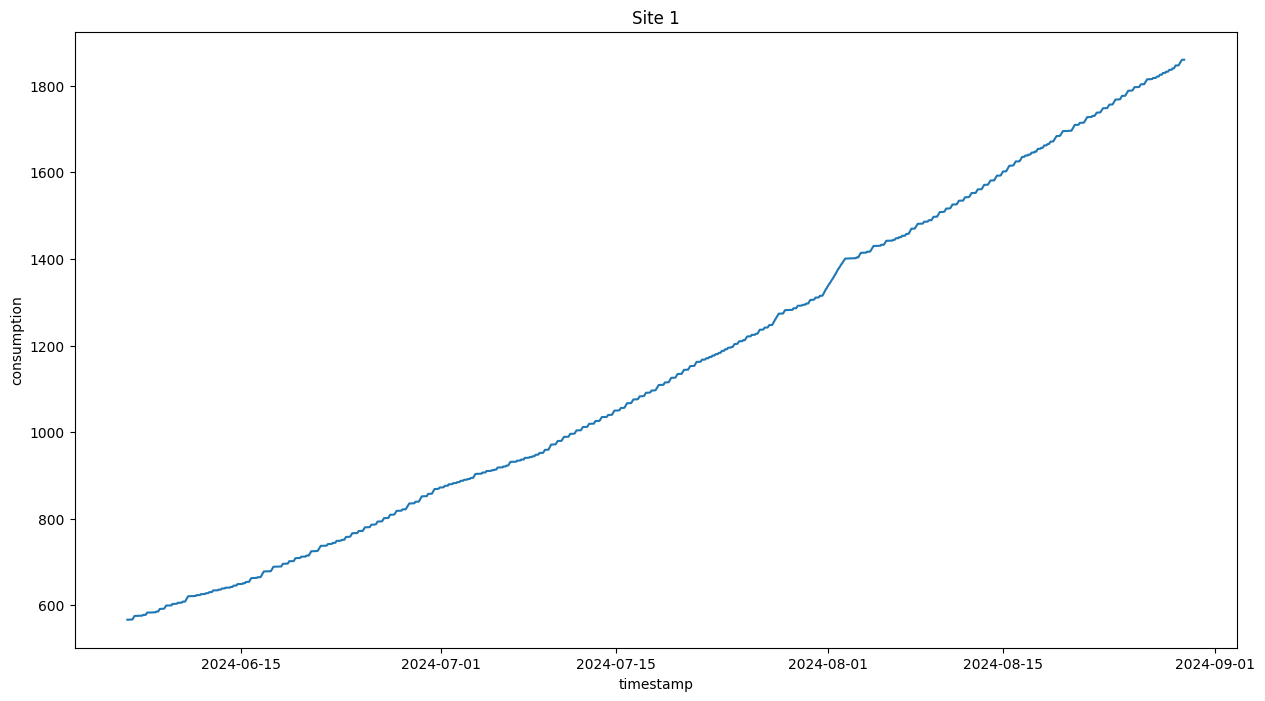

In [22]:
df_site_1 = df[df['site_id'] == 105][['site_id', 'timestamp', 'consumption']].reset_index(drop=True).copy()
sns.lineplot(data=df_site_1, x='timestamp', y='consumption')
plt.title('Site 1');

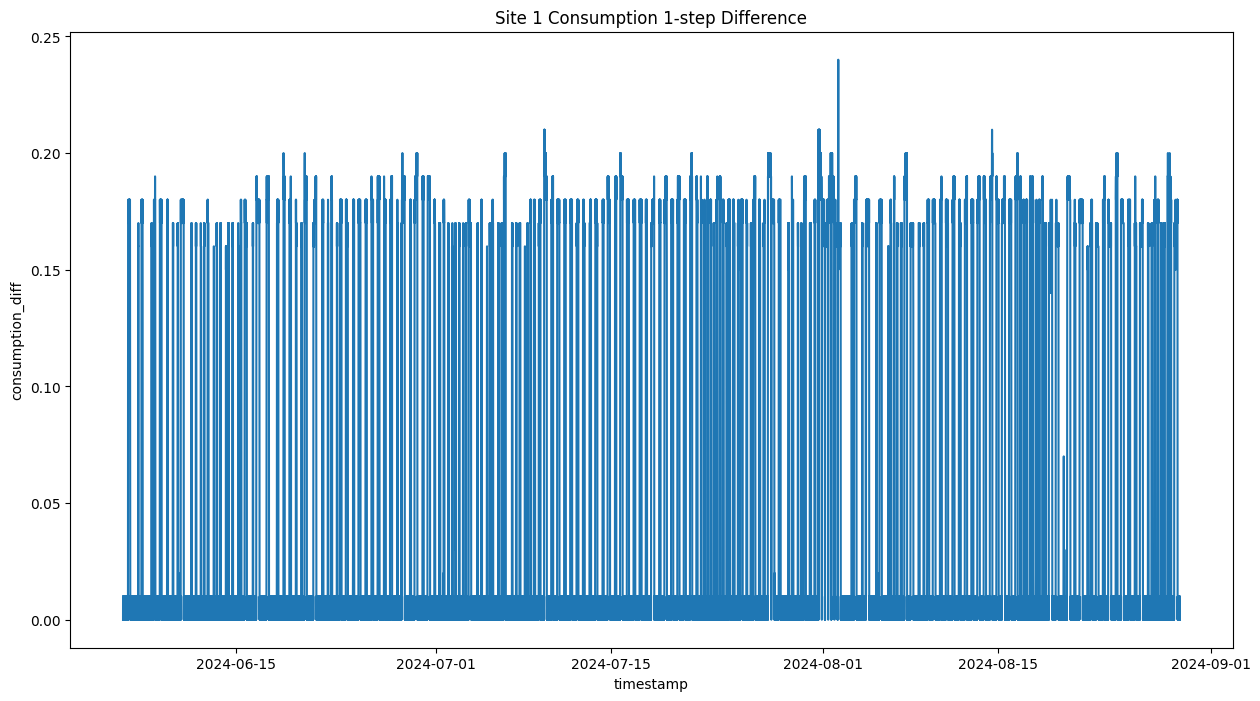

In [23]:
df_site_1['consumption_diff'] = df_site_1['consumption'].diff()
sns.lineplot(data=df_site_1, x='timestamp', y='consumption_diff')
plt.title('Site 1 Consumption 1-step Difference');


Site #2

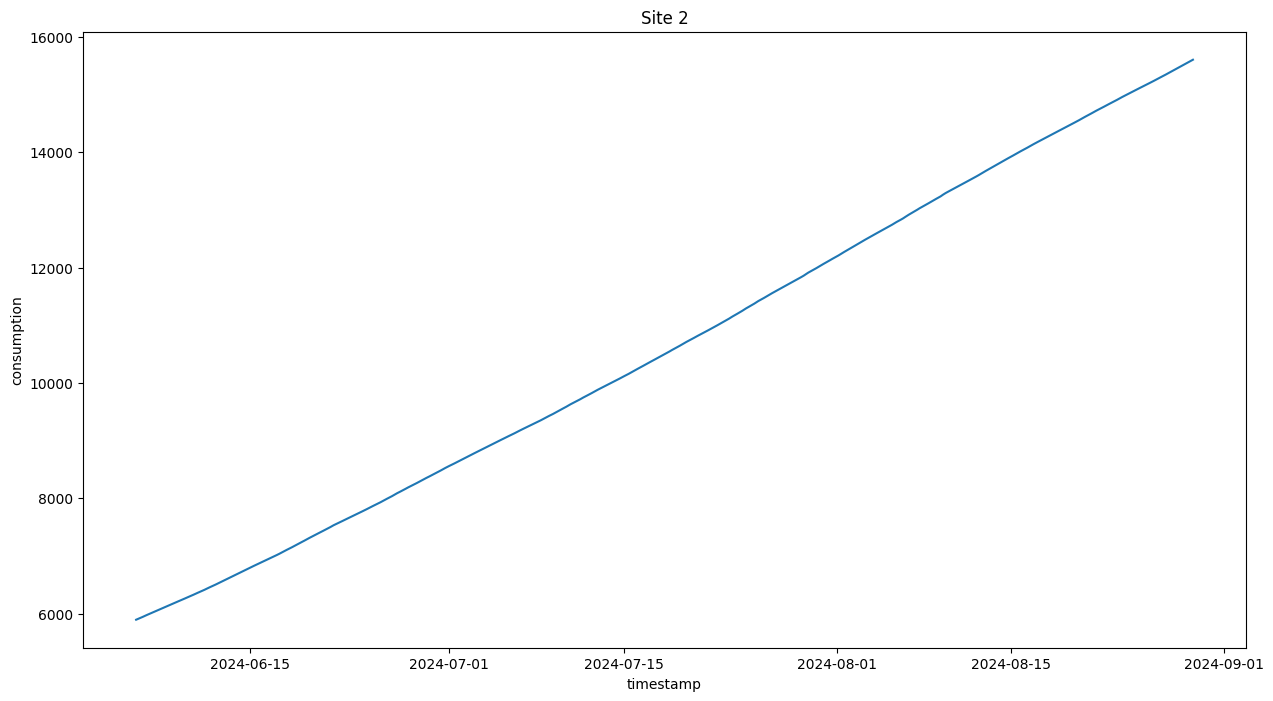

In [24]:
df_site_2 = df[df['site_id'] == 109][['site_id', 'timestamp', 'consumption']].reset_index(drop=True).copy()
sns.lineplot(data=df_site_2, x='timestamp', y='consumption')
plt.title('Site 2');

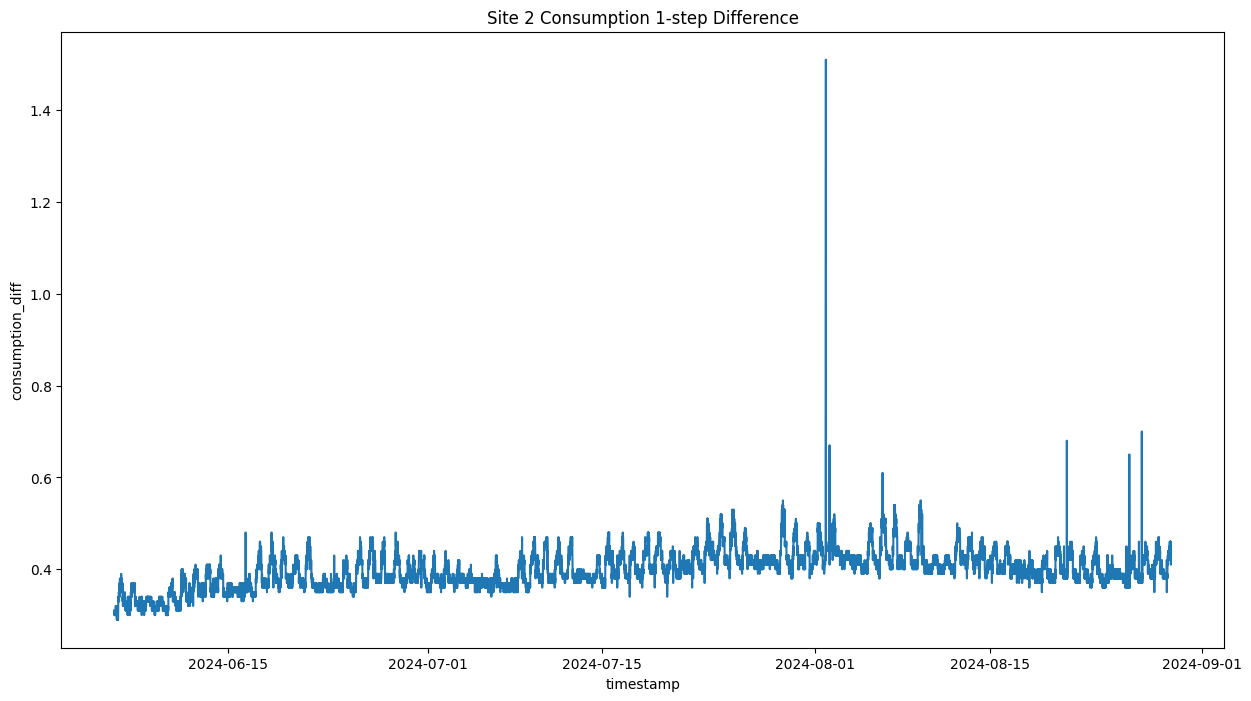

In [25]:
df_site_2['consumption_diff'] = df_site_2['consumption'].diff()
sns.lineplot(data=df_site_2, x='timestamp', y='consumption_diff')
plt.title('Site 2 Consumption 1-step Difference');

Site #3

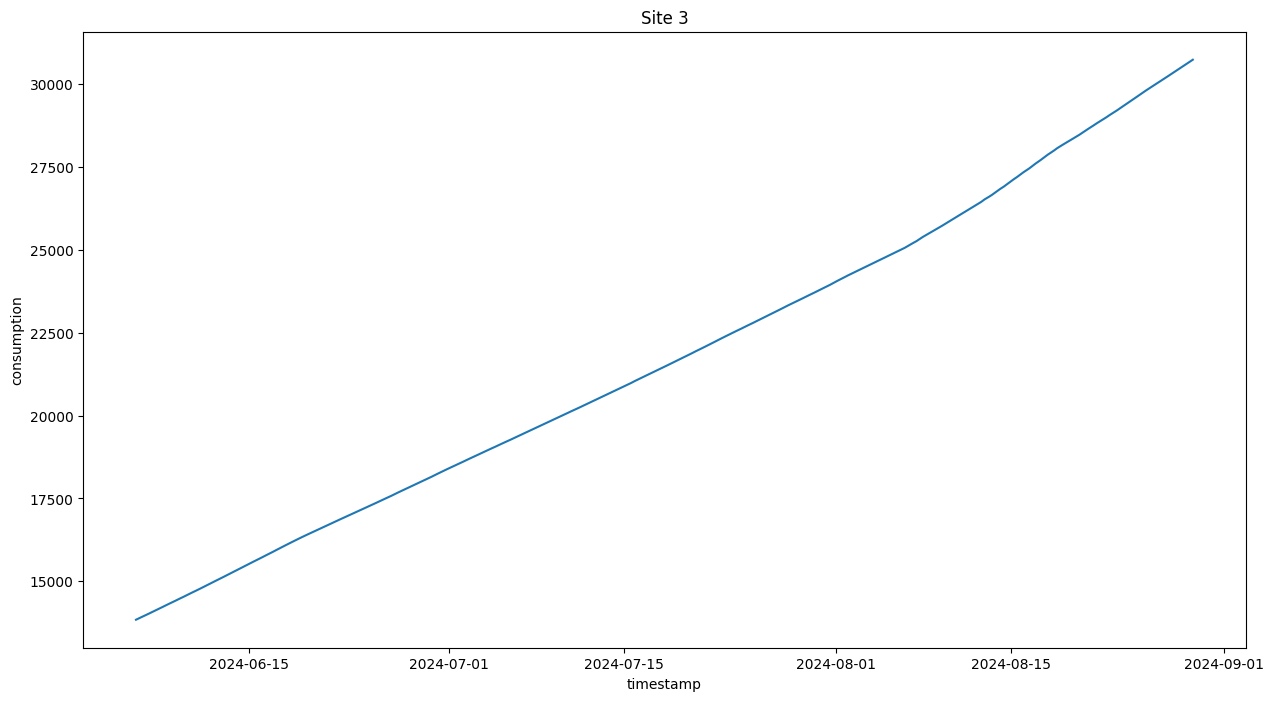

In [26]:
df_site_3 = df[df['site_id'] == 113][['site_id', 'timestamp', 'consumption']].reset_index(drop=True).copy()
sns.lineplot(data=df_site_3, x='timestamp', y='consumption')
plt.title('Site 3');

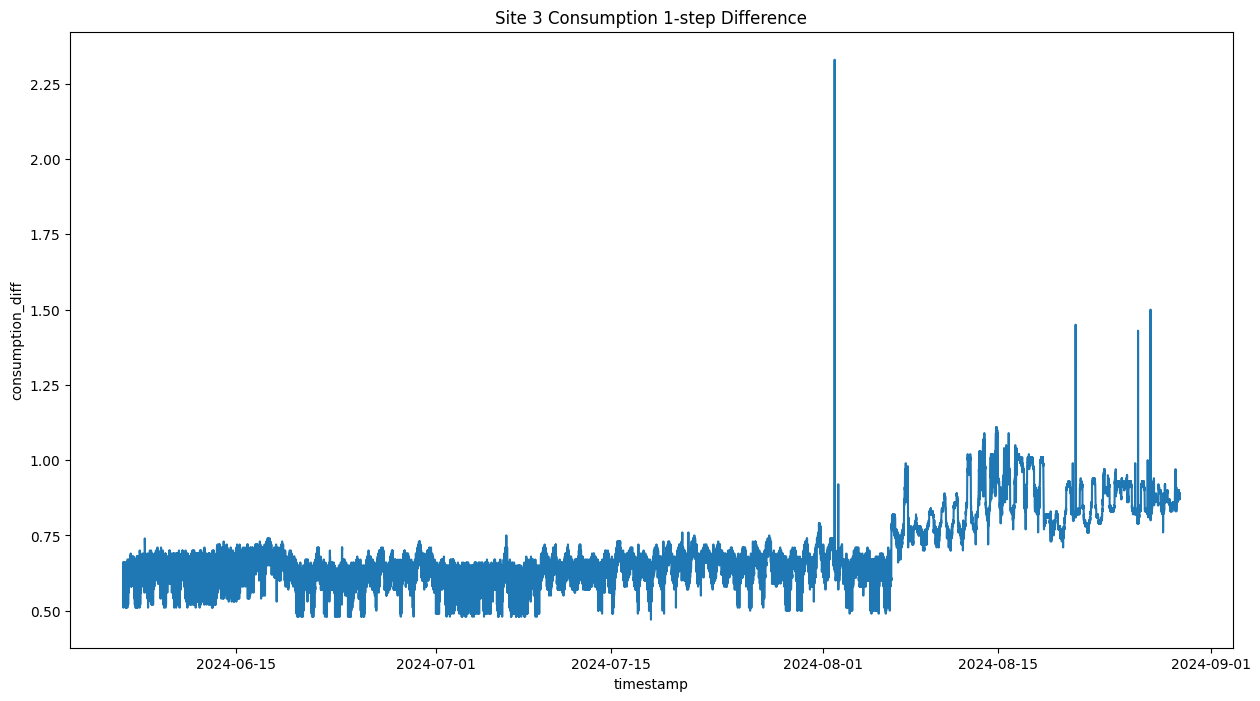

In [27]:
df_site_3['consumption_diff'] = df_site_3['consumption'].diff()
sns.lineplot(data=df_site_3, x='timestamp', y='consumption_diff')
plt.title('Site 3 Consumption 1-step Difference');

## Create list of sites

In [28]:
list_of_sites = [df_site_1, df_site_2, df_site_3]

## Peaks detection

In [29]:
from scipy.signal import find_peaks

def normalize_zscore(y):
    return (y - np.mean(y)) / np.std(y)

def robust_zscore(y):
    y = np.array(y)
    med = np.median(y)
    mad = np.median(np.abs(y - med))
    return (y - med) / (mad if mad > 1e-6 else 1)

def plot_spikes_and_drops(x, y, title="Signal with Spikes and Drops", prominence=1.0, robust=False):

    if robust:
        y_pred_norm = robust_zscore(y)
    else:
        y_pred_norm = normalize_zscore(y)
    peaks, _ = find_peaks(y_pred_norm, prominence=prominence)  # use normalized threshold
    drops, _ = find_peaks(-y_pred_norm, prominence=prominence)  # use normalized threshold

    plt.figure(figsize=(15, 9))
    plt.plot(x, y, label="Signal", color="gray")
    plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
    plt.plot(x[drops], y[drops], "bv", label="Drops")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

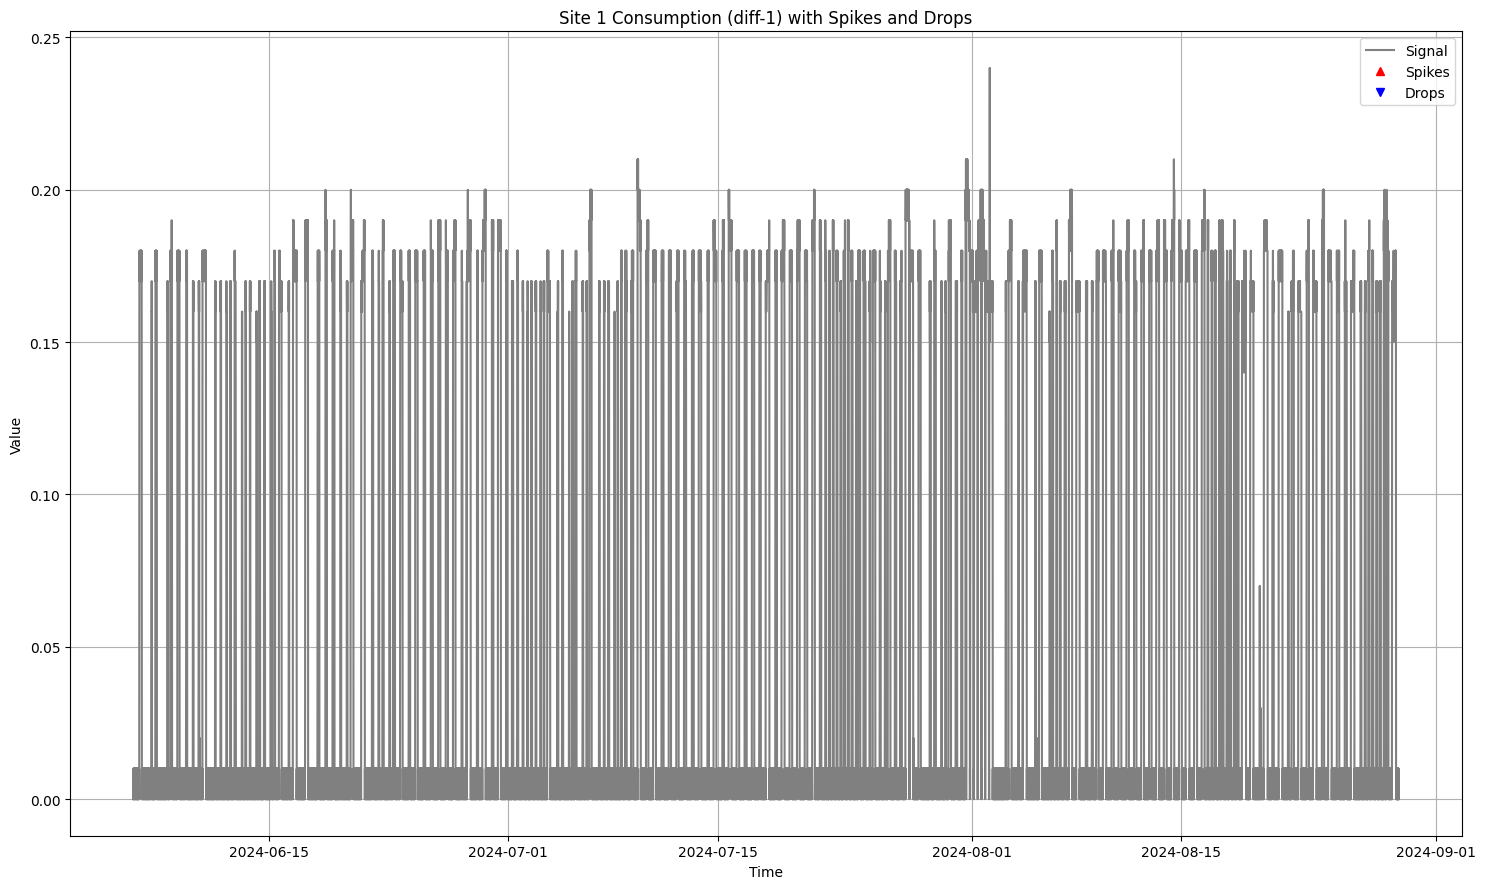

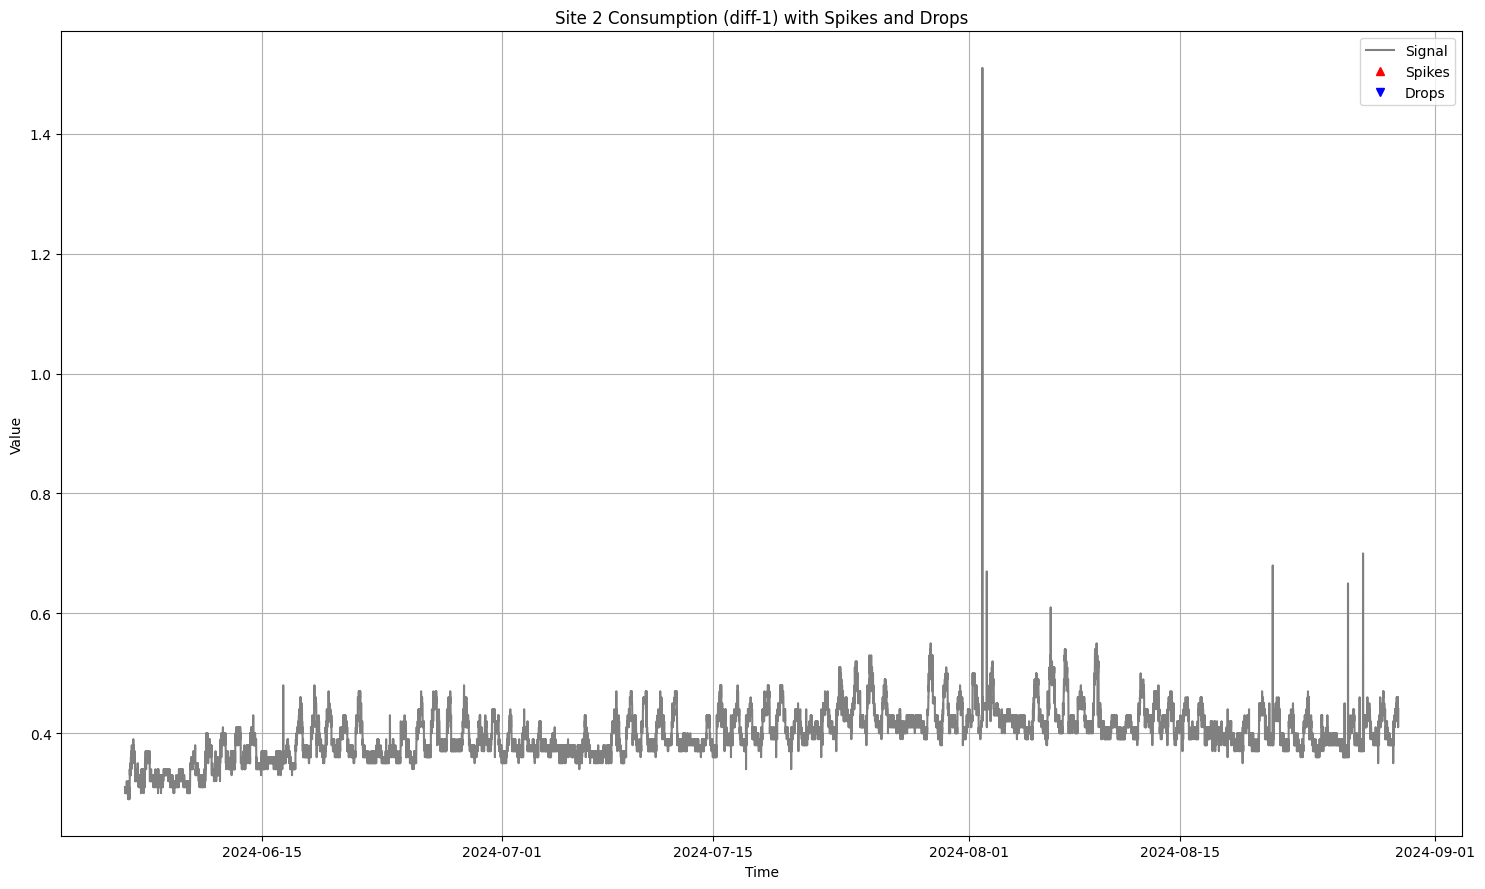

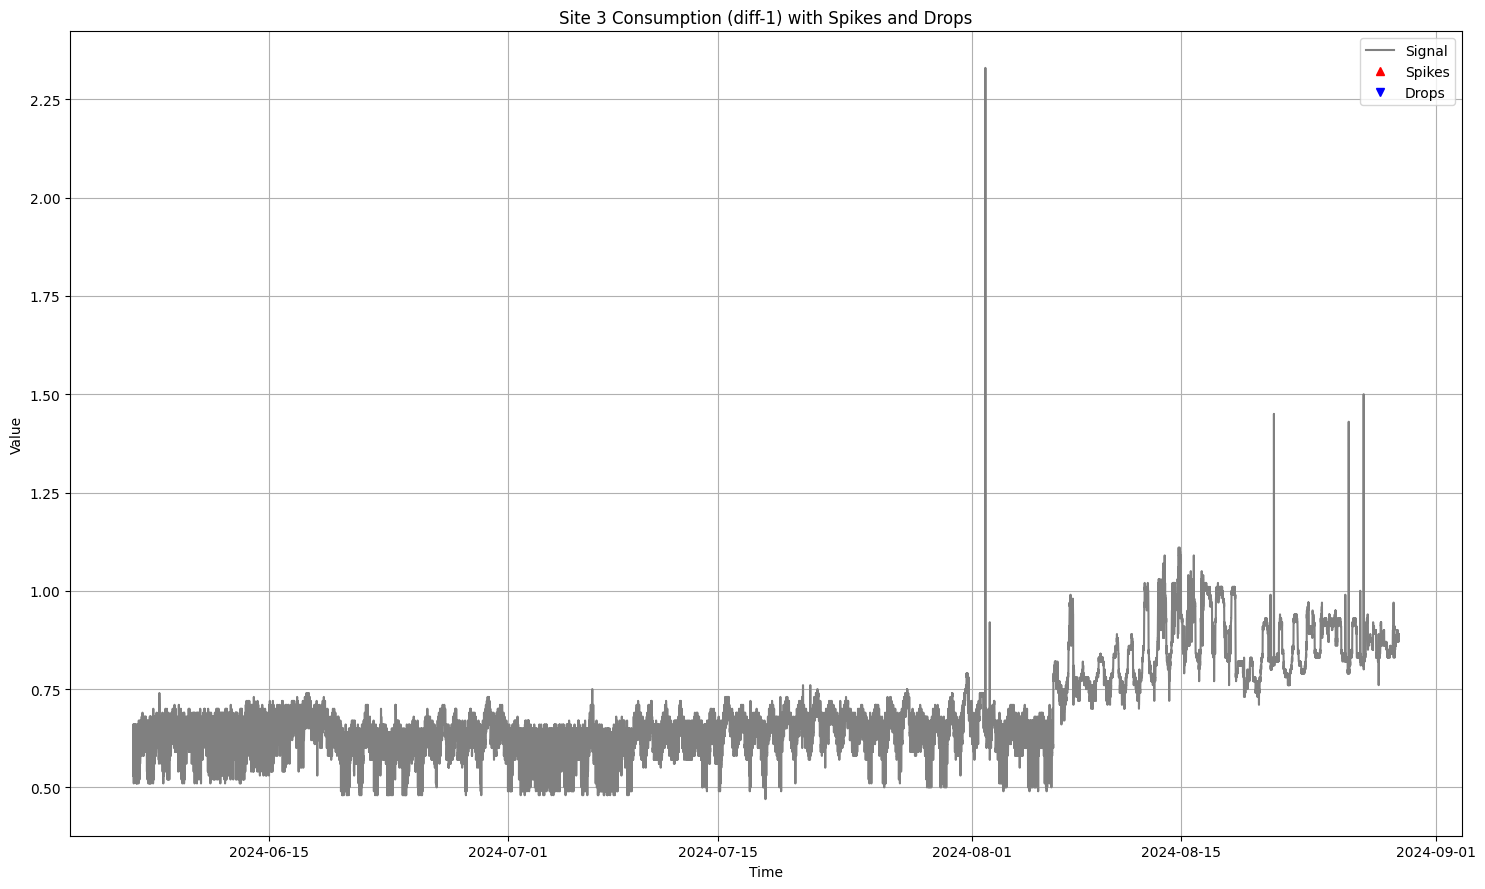

In [30]:
for i, site_df in enumerate(list_of_sites, 1):
    plot_spikes_and_drops(site_df['timestamp'],
                        site_df['consumption_diff'], 
                        title=f"Site {i} Consumption (diff-1) with Spikes and Drops",
                        prominence=0.002, robust=True)

## Hourly Analysis by Site

In [31]:
def create_hourly_analysis_for_site(site_df, diff=False):
    """Create hourly aggregated data for a specific site"""
    # Group by hour
    site_df = site_df.copy()
    site_df['consumption'] = site_df['consumption'].diff() if diff else site_df['consumption']
    site_hour = site_df.groupby(site_df['timestamp'].dt.floor('h'))
    
    # Create index for full time range of this site
    full_range = pd.DataFrame(
        index=pd.date_range(
            site_df['timestamp'].min().floor('h'),
            site_df['timestamp'].max().floor('h'), 
            freq='h'
        )
    )
    
    # Join with hourly aggregated consumption data
    consumption_hour = full_range.join(site_hour['consumption'].mean(), how='left').squeeze()
    
    return consumption_hour

In [32]:
# Create hourly data for each site
site_diff_hourly_data = {}
for i, site_df in enumerate(list_of_sites, 1):
    site_diff_hourly_data[f'site_{i}'] = create_hourly_analysis_for_site(site_df, diff=True)
    print(f"Site {i} hourly data shape: {site_diff_hourly_data[f'site_{i}'].shape}")

Site 1 hourly data shape: (2031,)
Site 2 hourly data shape: (2031,)
Site 3 hourly data shape: (2031,)


In [33]:
# Collect statistics for each site's hourly data into a single DataFrame
stats_list = []
for i in range(1, len(site_diff_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_diff_hourly_data:
        stats = site_diff_hourly_data[site_key].describe()
        stats.name = f'Site {i}'
        stats_list.append(stats)

pd.concat(stats_list, axis=1)

,Site 1,Site 2,Site 3
count,2031.000000,2031.000000,2031.000000
mean,0.053089,0.398450,0.693412
std,0.071202,0.037649,0.110794
min,0.003333,0.301667,0.559167
25%,0.003333,0.374167,0.615833
50%,0.004167,0.397500,0.646667
75%,0.119583,0.419167,0.751667
max,0.203333,0.556667,1.090000


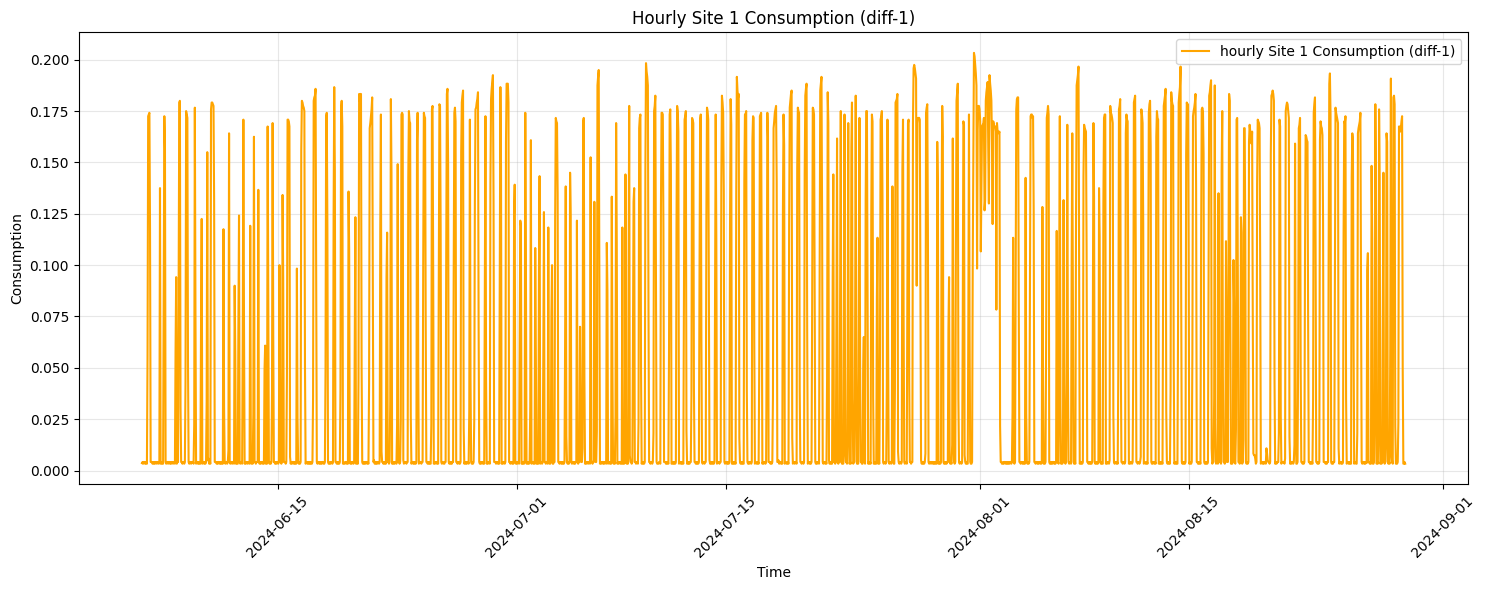

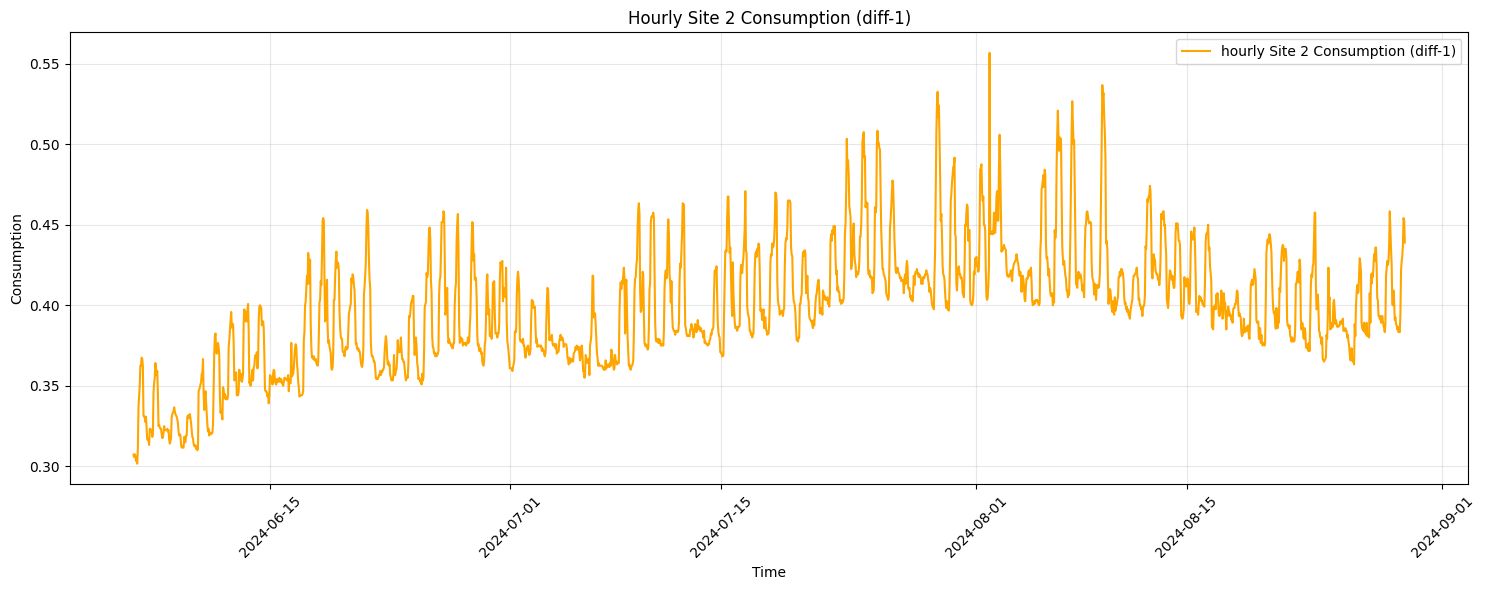

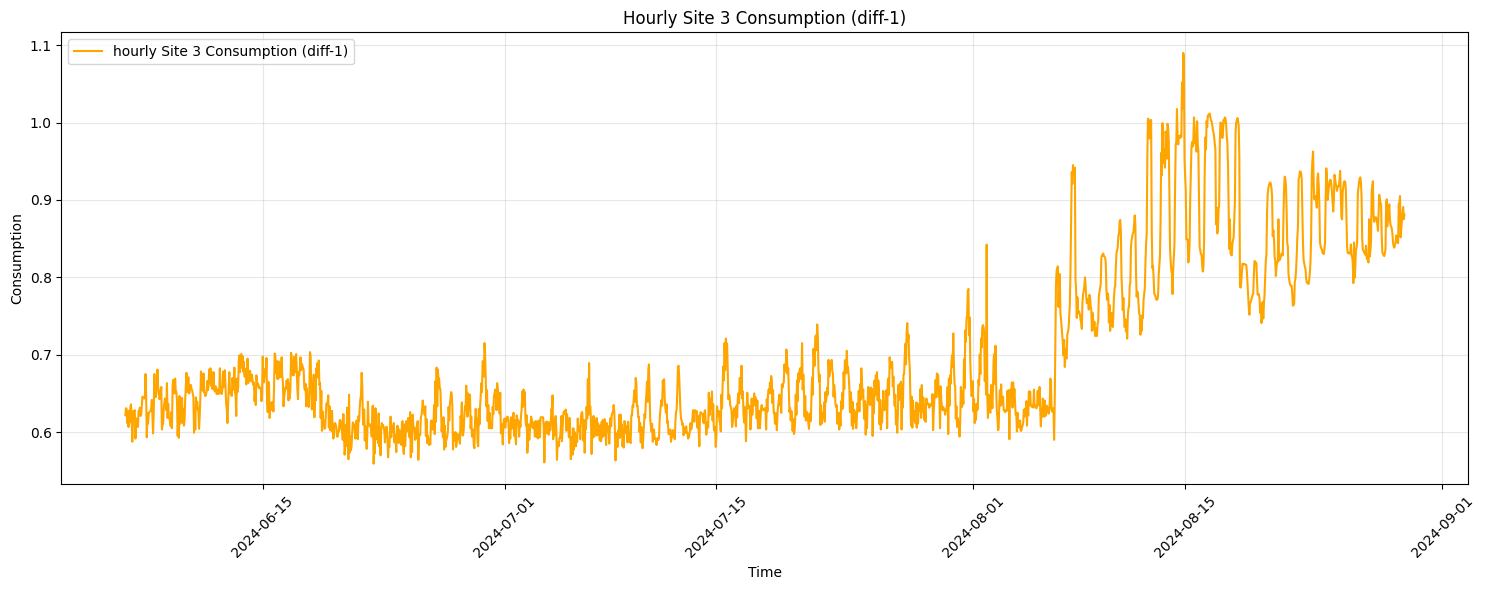

In [34]:
def plot_hourly_data(series, title, color='blue'):
    """Plot hourly data with missing values marked"""
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else 0
    
    plt.figure(figsize=(15, 6))
    sns.lineplot(x=series.index, y=series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    if series.isna().any():
        missing_mask = series.isna()
        plt.scatter(
            x=series[missing_mask].index,
            y=[series.min()-0.01]*series[missing_mask].shape[0],
            color='red',
            marker='x',
            label='missing',
            s=50
        )
    
    plt.title(f"Hourly {title}")
    plt.xlabel("Time")
    plt.ylabel("Consumption")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Plot hourly data for each site
for i in range(1, len(site_diff_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_diff_hourly_data:
        plot_hourly_data(site_diff_hourly_data[site_key], f'Site {i} Consumption (diff-1)', color='orange')

### Detect peaks in hourly consumption

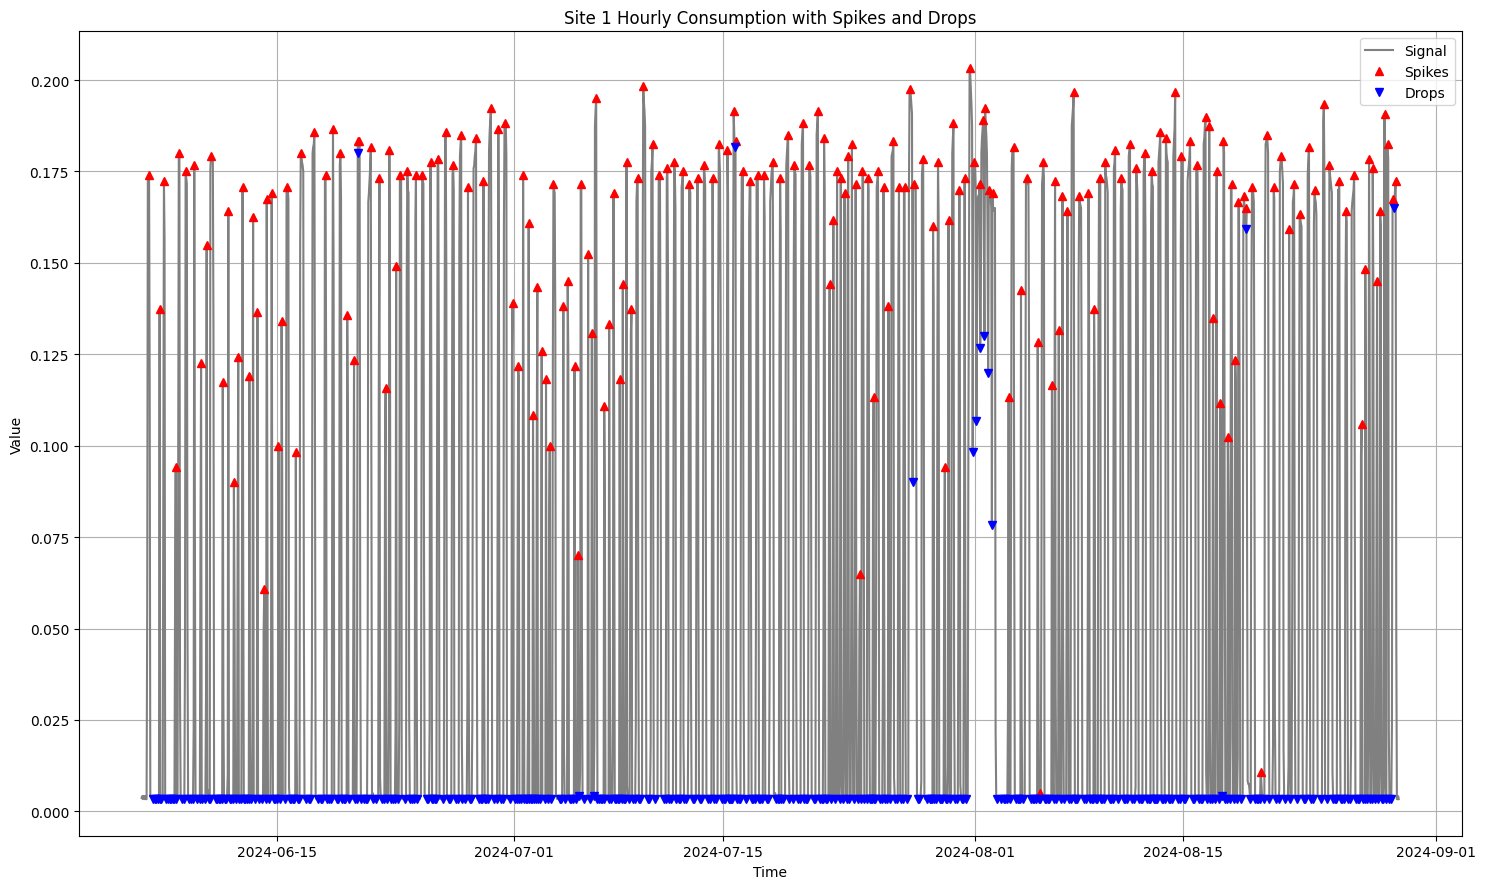

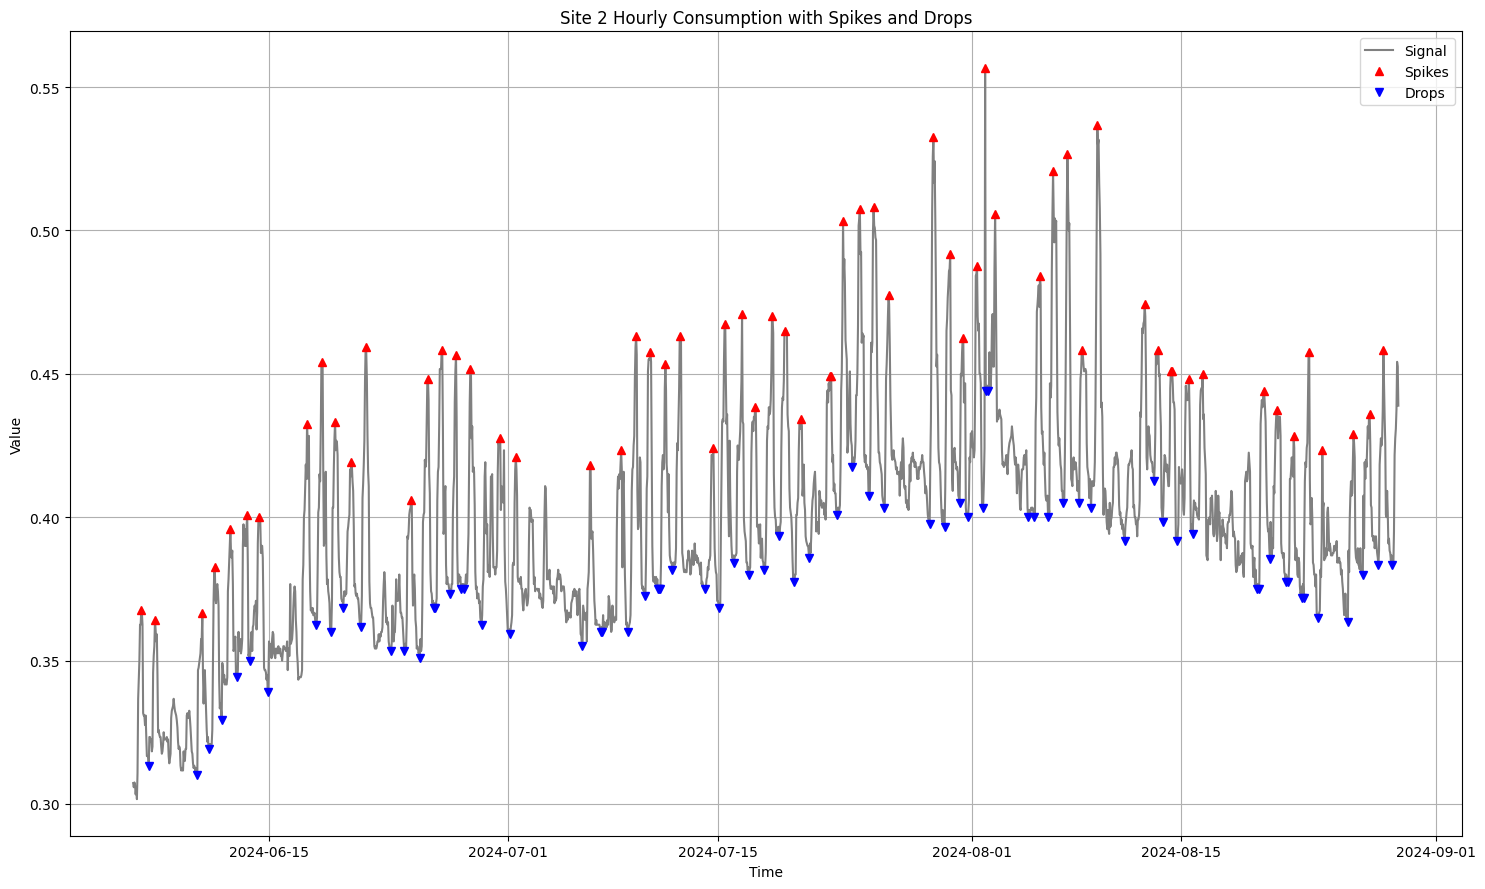

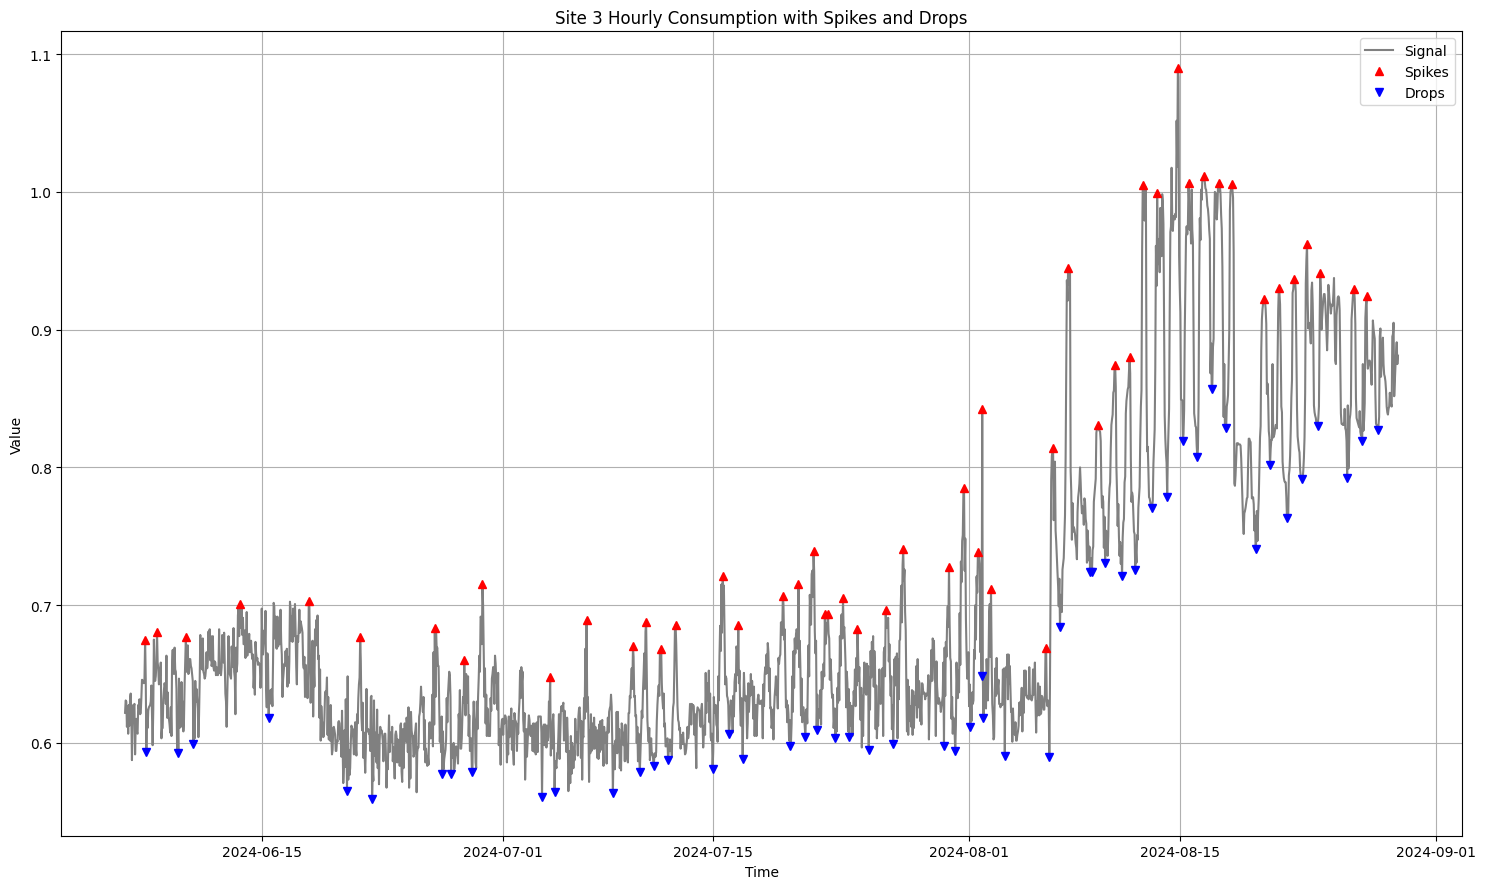

In [35]:
# Detect peaks in hourly consumption for each site
for i in range(1, len(site_diff_hourly_data.keys())+1):
    site_key = f'site_{i}'
    if site_key in site_diff_hourly_data:
        hourly_data = site_diff_hourly_data[site_key].dropna()
        if len(hourly_data) > 0:
            plot_spikes_and_drops(
                hourly_data.index,
                hourly_data.values, 
                title=f"Site {i} Hourly Consumption with Spikes and Drops",
                prominence=2.0, robust=True
            )

## Weekly Patterns Analysis by Site


Analyzing weekly patterns for Site 1:


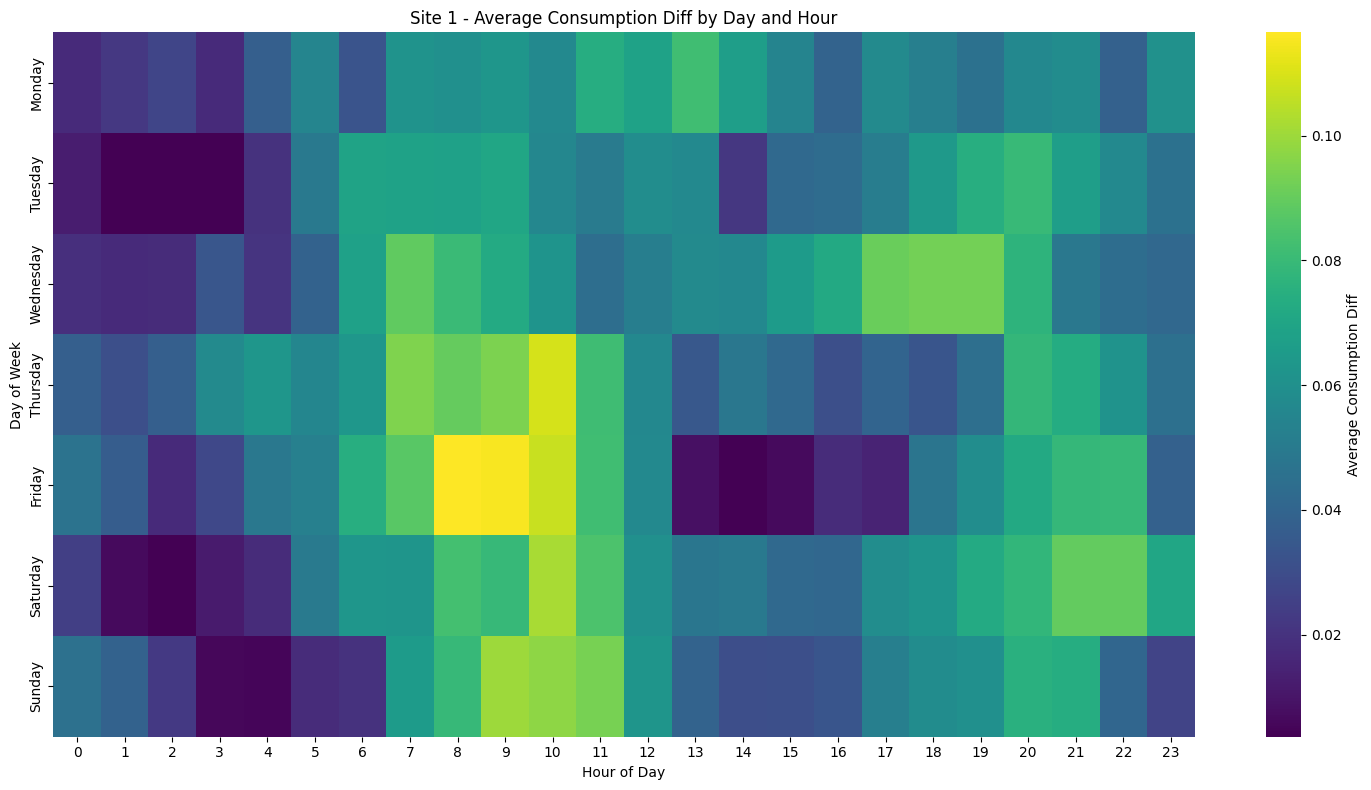


Analyzing weekly patterns for Site 2:


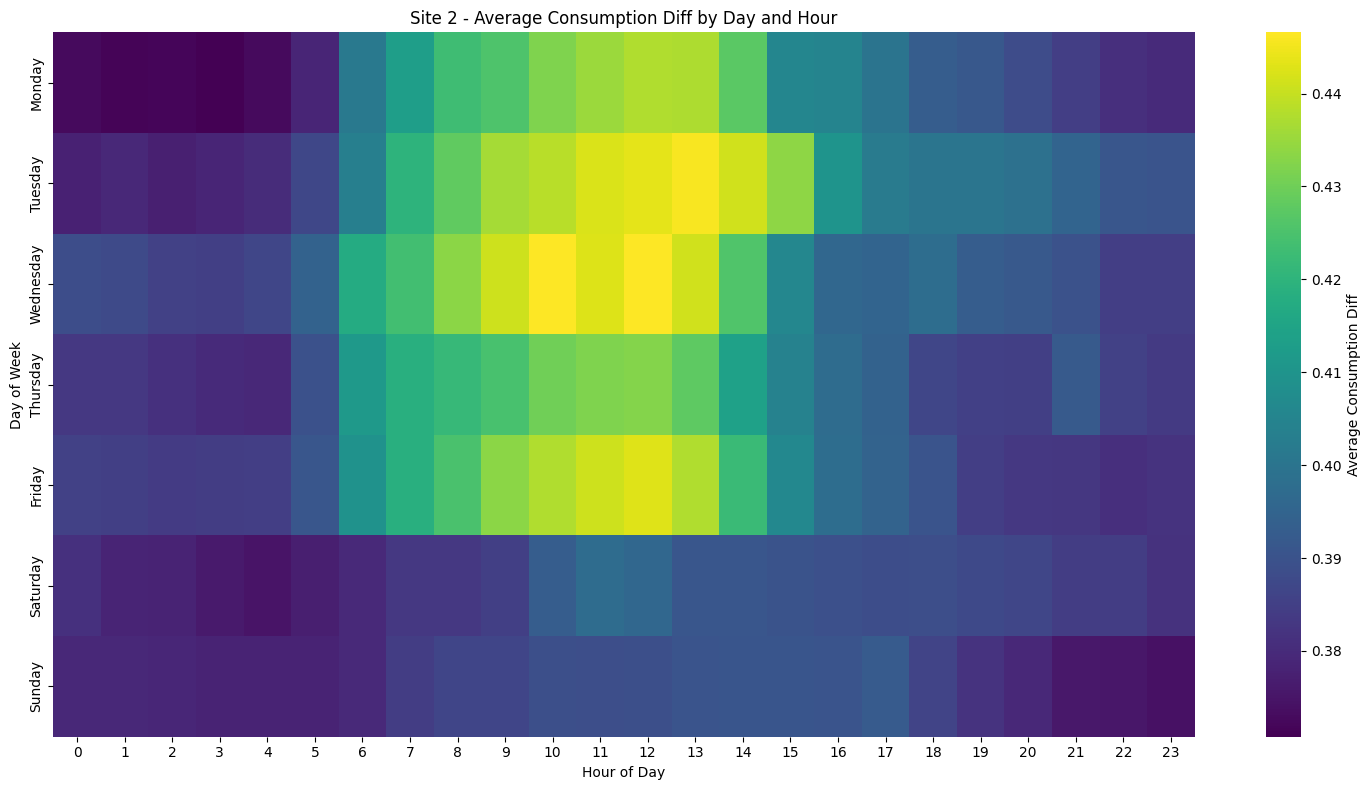


Analyzing weekly patterns for Site 3:


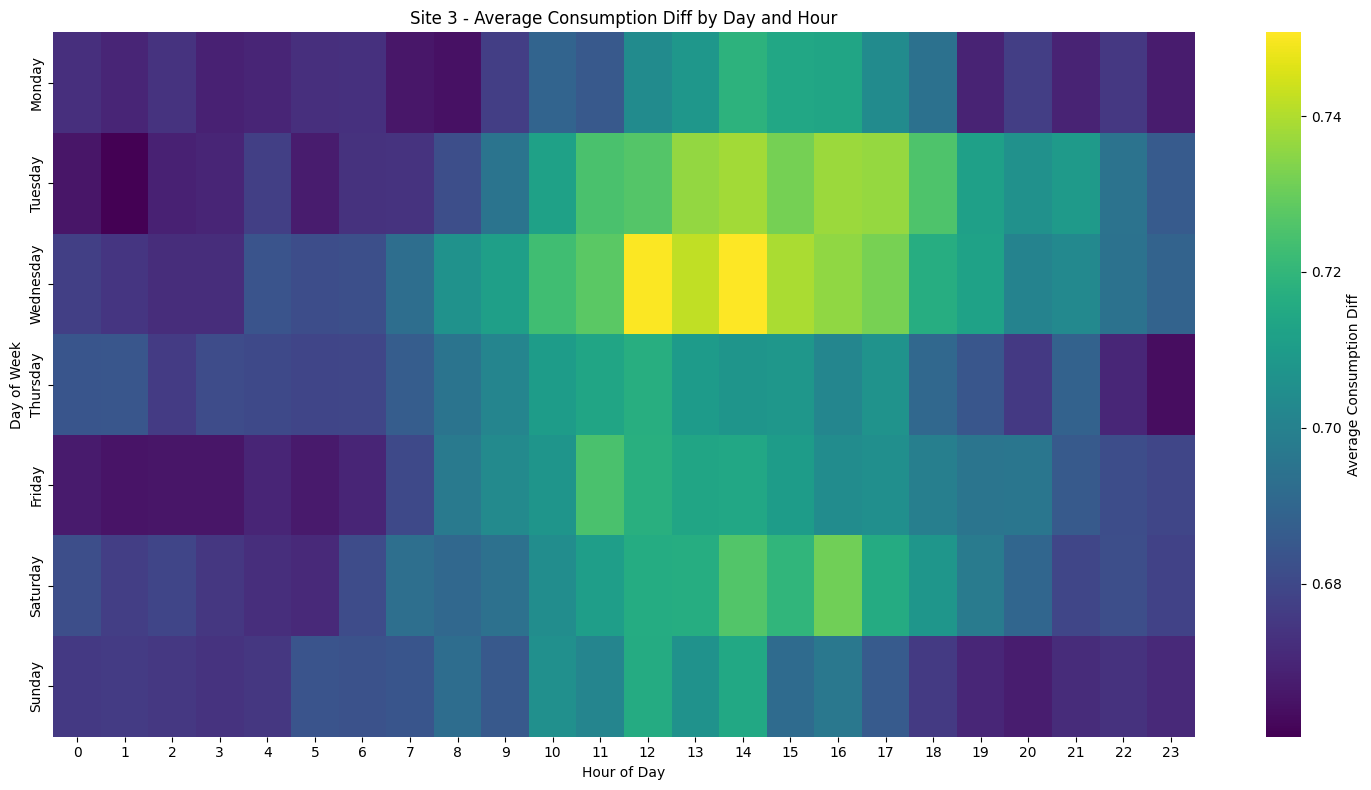

In [36]:
def analyze_weekly_patterns_for_site(df, site_id, diff=True):
    """Analyze weekly patterns for a specific site"""
    # Extract day of week and hour if not already present
    if 'day_of_week' not in df.columns or 'hour' not in df.columns:
        df['day_of_week'] = df['timestamp'].dt.day_name()
        df['hour'] = df['timestamp'].dt.hour

    # Group by day of week and hour
    agg_col = 'consumption_diff' if diff else 'consumption'
    daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
        agg_col: 'mean'
    }).reset_index()

    # Order days correctly
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
    daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

    # Create pivot table for heatmap
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values=agg_col)

    # Plot heatmap
    plt.figure(figsize=(15, 8))
    label = 'Average Consumption Diff' if diff else 'Average Consumption'
    sns.heatmap(pivot_table, cmap='viridis', annot=False, cbar_kws={'label': label})
    plt.title(f"Site {site_id} - {label} by Day and Hour")
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

    return daily_patterns, pivot_table

# Analyze weekly patterns for each site
weekly_patterns = {}
for i, site_df in enumerate(list_of_sites, 1):
    print(f"\nAnalyzing weekly patterns for Site {i}:")
    patterns_diff, pivot_diff = analyze_weekly_patterns_for_site(site_df, i, diff=True)
    weekly_patterns[f'site_{i}'] = {
        'patterns_diff': patterns_diff,
        'pivot_diff': pivot_diff
    }

## Autocorrelation Analysis by Site


Autocorrelation Analysis for Site 1 (diff-1):


<Figure size 1500x600 with 0 Axes>

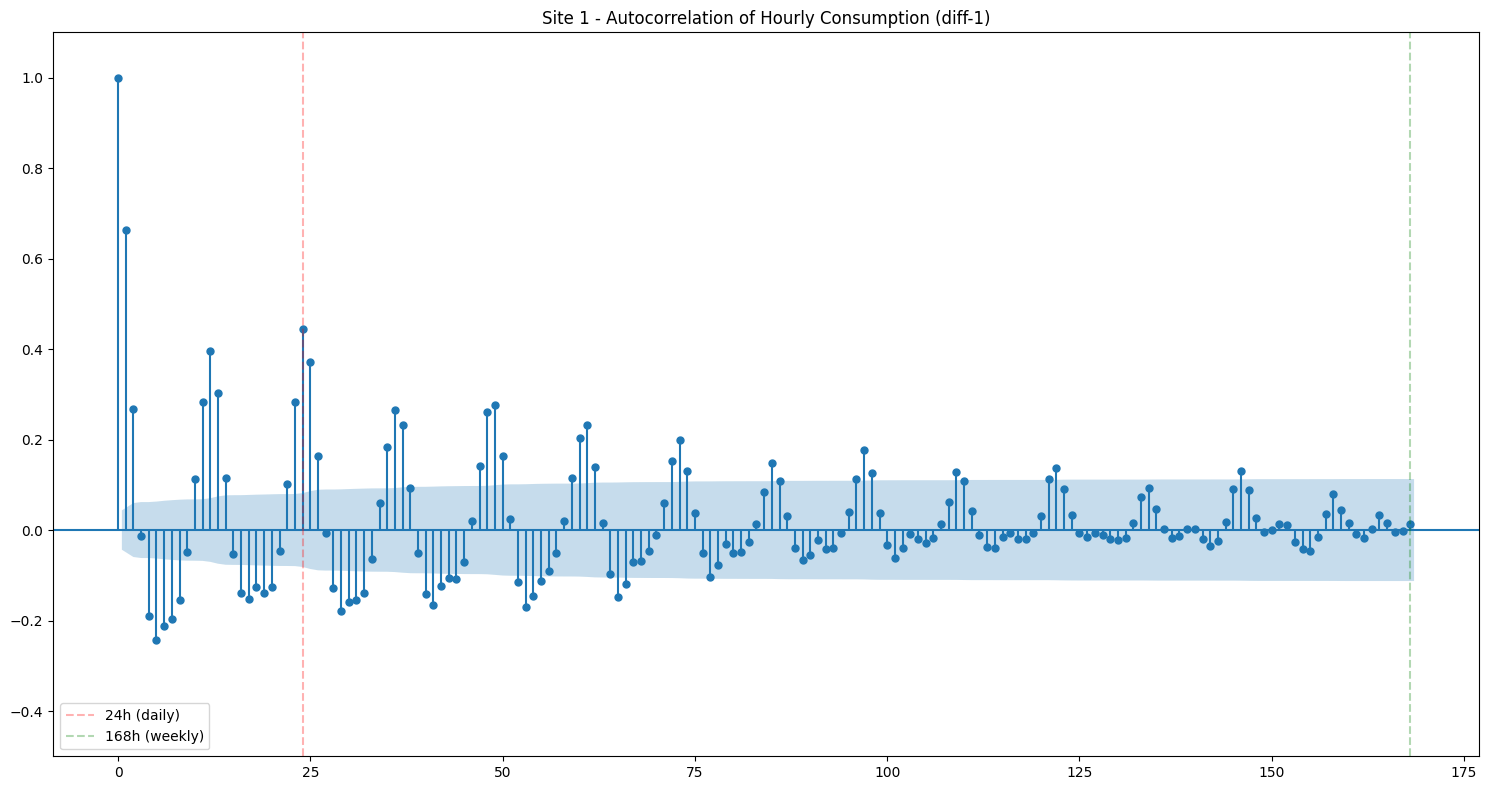

Site 1 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.663
  Lag 24: +0.444
  Lag 12: +0.396
  Lag 25: +0.371
  Lag 13: +0.304
  Lag 23: +0.284
  Lag 11: +0.282


<Figure size 1500x600 with 0 Axes>

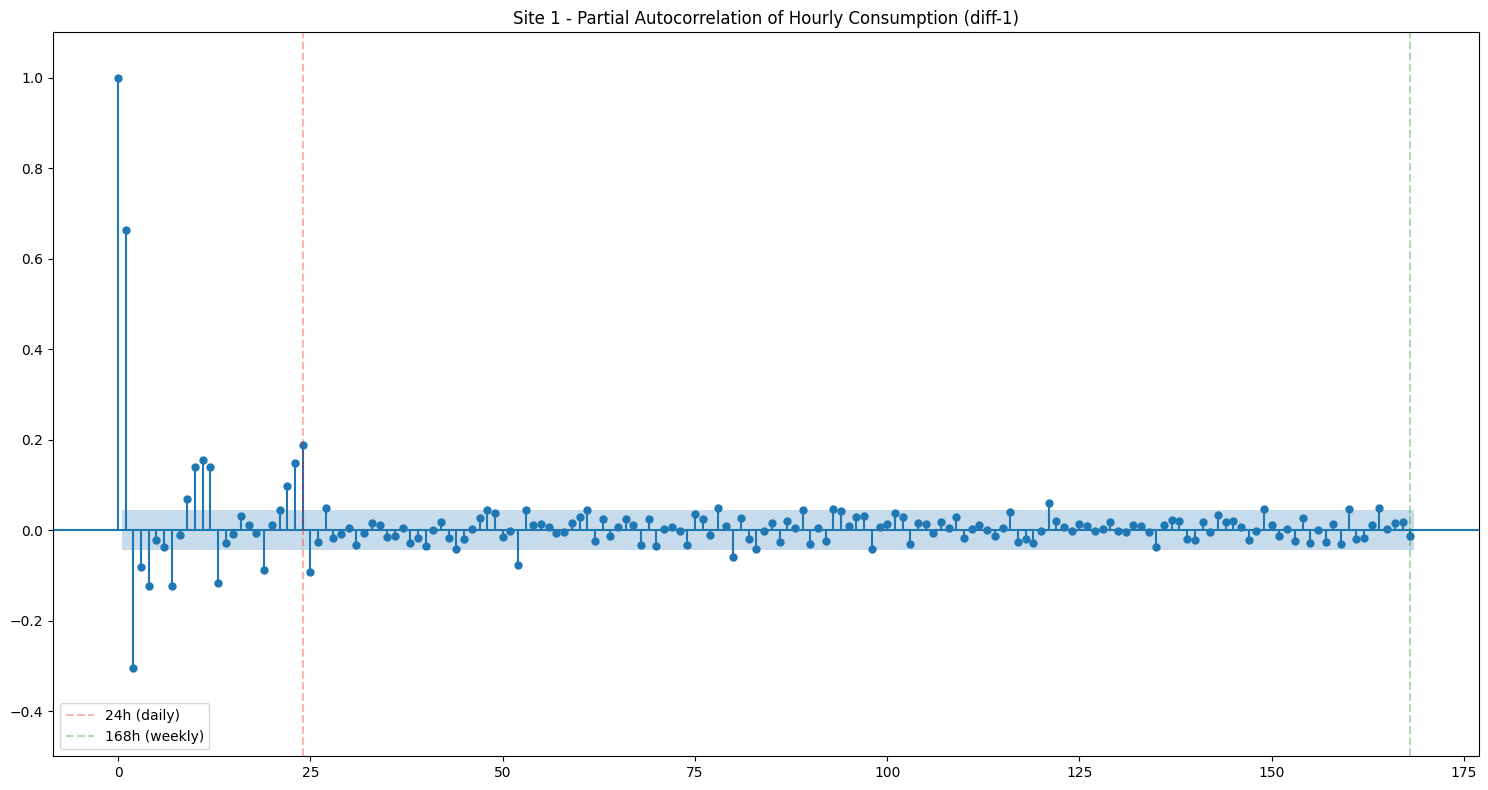

Site 1 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.663
  Lag 2: -0.306
  Lag 24: +0.192
  Lag 11: +0.156
  Lag 23: +0.150
  Lag 12: +0.141
  Lag 10: +0.140

Autocorrelation Analysis for Site 2 (diff-1):


<Figure size 1500x600 with 0 Axes>

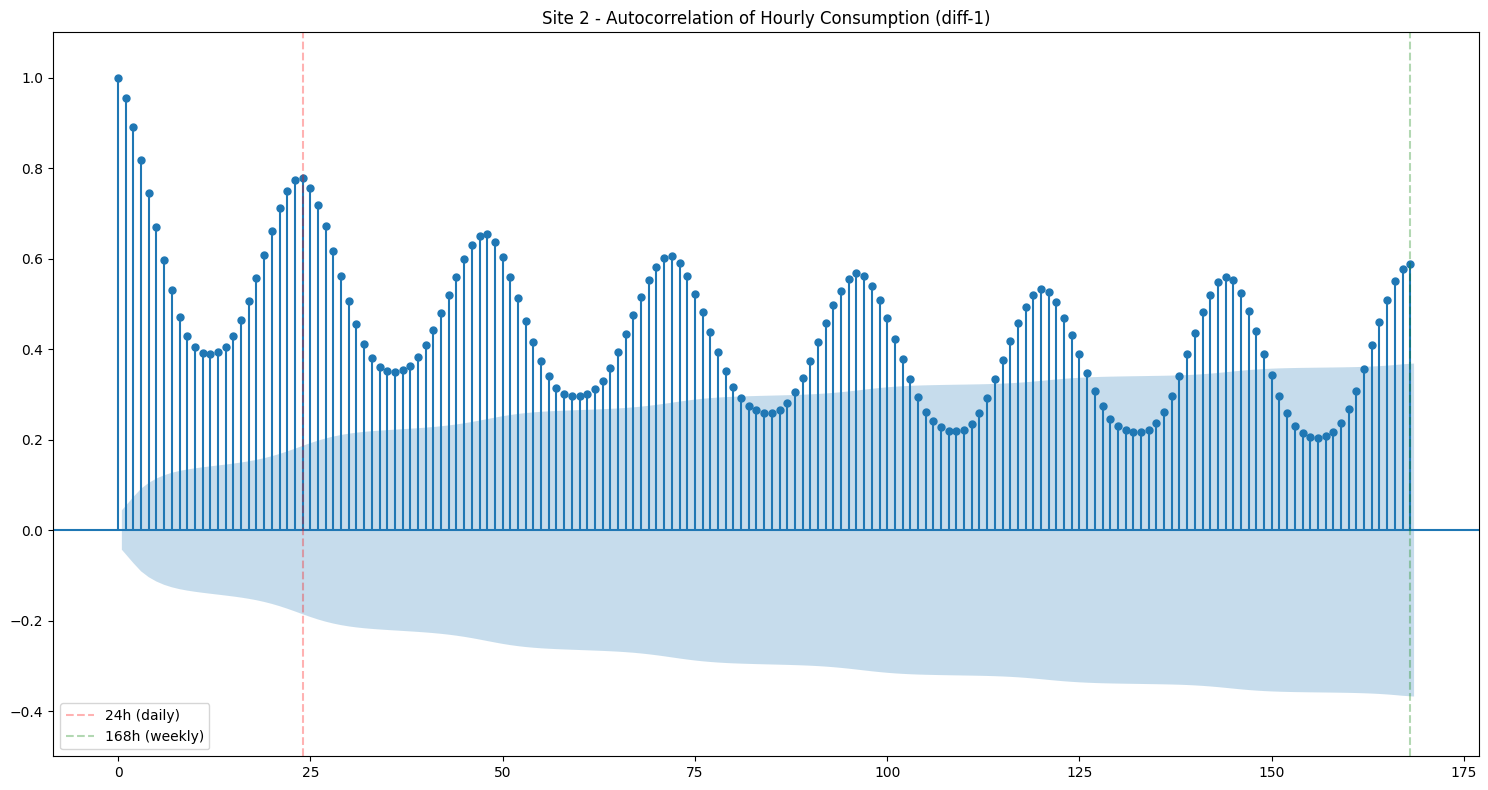

Site 2 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.954
  Lag 2: +0.890
  Lag 3: +0.818
  Lag 24: +0.777
  Lag 23: +0.774
  Lag 25: +0.757
  Lag 22: +0.750


<Figure size 1500x600 with 0 Axes>

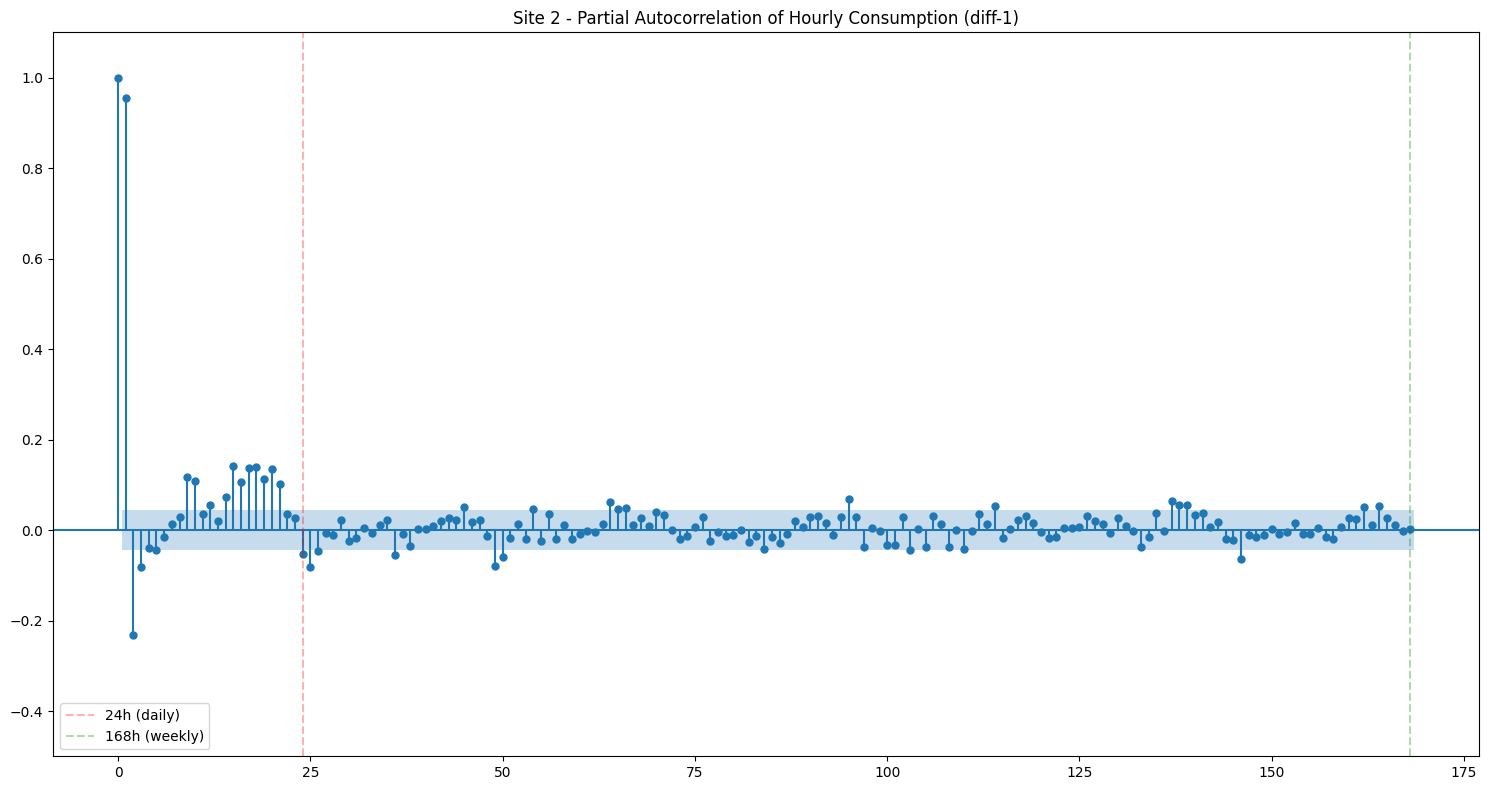

Site 2 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.955
  Lag 2: -0.235
  Lag 15: +0.144
  Lag 18: +0.142
  Lag 17: +0.140
  Lag 20: +0.138
  Lag 9: +0.119

Autocorrelation Analysis for Site 3 (diff-1):


<Figure size 1500x600 with 0 Axes>

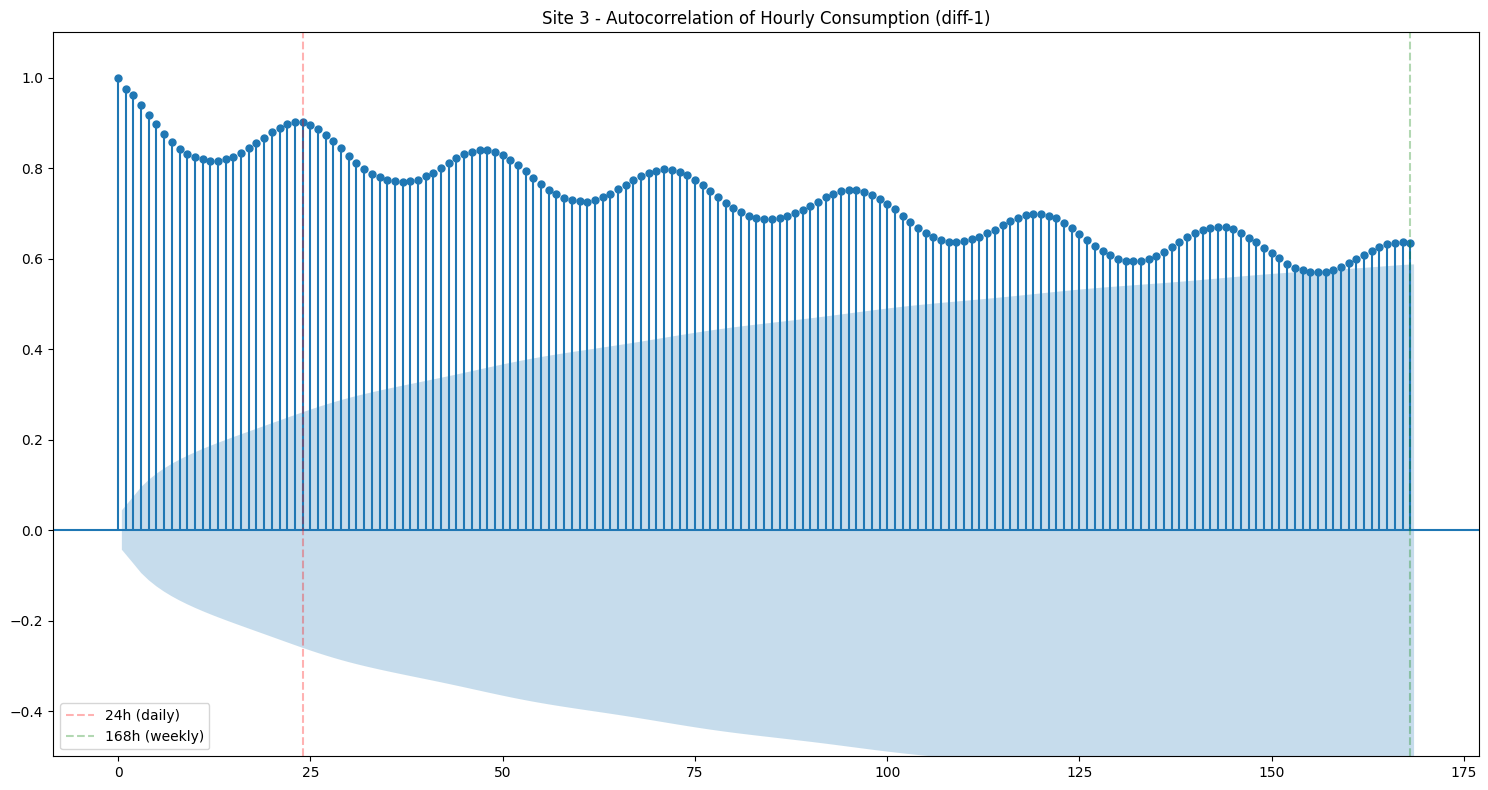

Site 3 - Top 7 ACF lags (abs ranking):
  Lag 1: +0.975
  Lag 2: +0.961
  Lag 3: +0.939
  Lag 4: +0.918
  Lag 23: +0.902
  Lag 24: +0.901
  Lag 5: +0.898


<Figure size 1500x600 with 0 Axes>

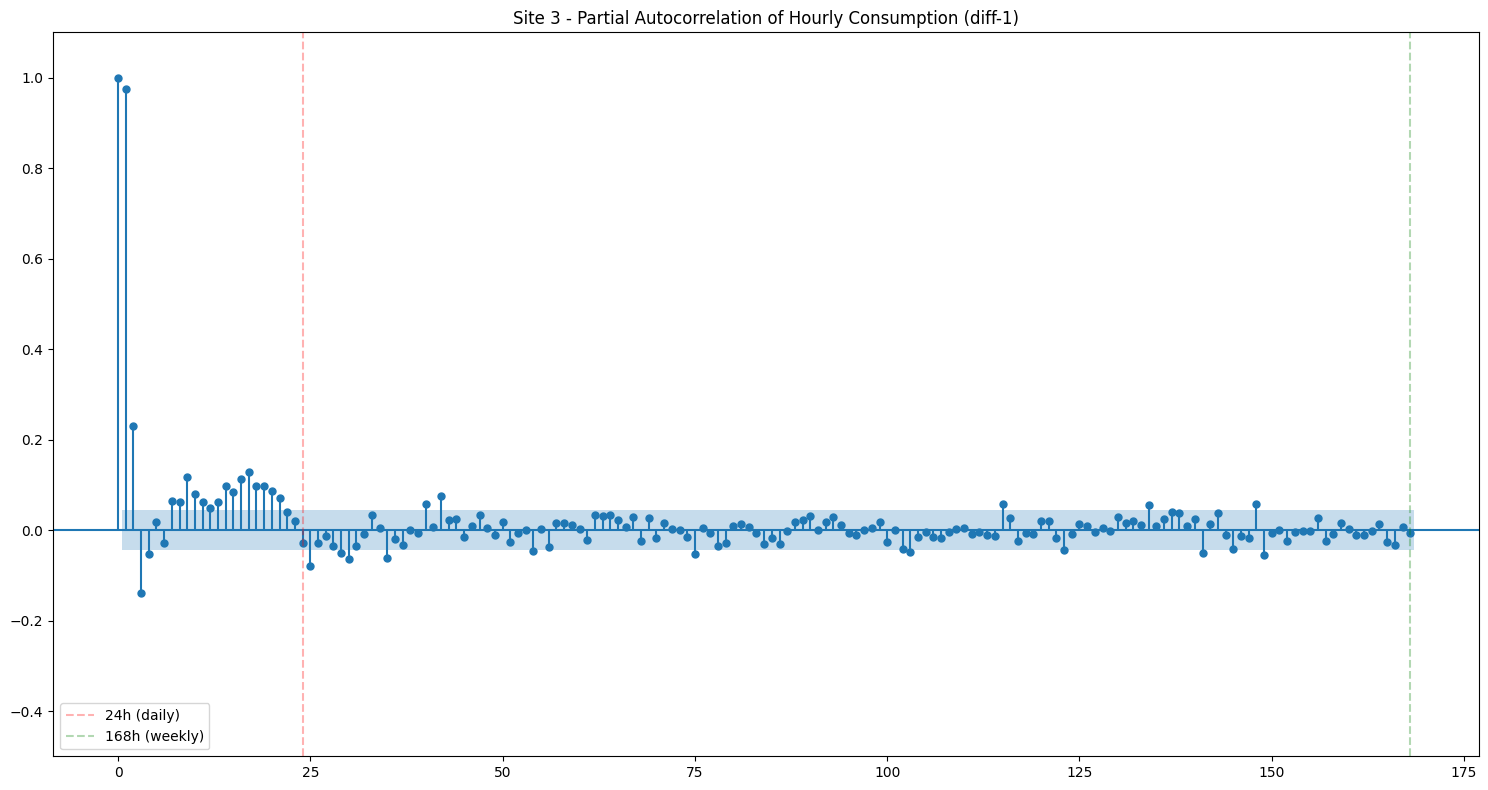

Site 3 - Top 7 PACF lags (abs ranking):
  Lag 1: +0.975
  Lag 2: +0.235
  Lag 3: -0.141
  Lag 17: +0.135
  Lag 9: +0.120
  Lag 16: +0.118
  Lag 18: +0.104


In [37]:
from statsmodels.tsa.stattools import acf, pacf

def plot_acf_pacf_consumption(series, site_id, lags=24*7):
    """Plot ACF and PACF for consumption data and print top correlations"""

    # Handle missing values
    fill_value = series.median() if not pd.isna(series.median()) else 0
    filled_series = series.fillna(fill_value)

    if len(filled_series) < lags:
        lags = len(filled_series) // 2

    # Compute ACF and PACF values
    acf_vals = acf(filled_series, nlags=lags, fft=True)
    pacf_vals = pacf(filled_series, nlags=lags)

    # Prepare lag indices (skip lag 0)
    lag_indices = np.arange(1, lags+1)
    acf_lags = acf_vals[1:]
    pacf_lags = pacf_vals[1:]

    # Get top 7 by absolute value for ACF and PACF
    def top_corr(lags_arr, vals_arr, top_n=7):
        abs_vals = np.abs(vals_arr)
        sorted_idx = np.argsort(-abs_vals)
        top_idx = sorted_idx[:top_n]
        return [(lags_arr[i], vals_arr[i]) for i in top_idx]

    # Plot ACF
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Site {site_id} - Autocorrelation of Hourly Consumption (diff-1)')
    plt.ylim(-0.5, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    if lags >= 24*7:
        plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Get top 7 by absolute value for ACF
    top_acf = top_corr(lag_indices, acf_lags)
    print(f"Site {site_id} - Top 7 ACF lags (abs ranking):")
    for lag, val in top_acf:
        print(f"  Lag {lag}: {val:+.3f}")

    # Plot PACF
    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Site {site_id} - Partial Autocorrelation of Hourly Consumption (diff-1)')
    plt.ylim(-0.5, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    if lags >= 24*7:
        plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Get top 7 by absolute value for PACF
    top_pacf = top_corr(lag_indices, pacf_lags)
    print(f"Site {site_id} - Top 7 PACF lags (abs ranking):")
    for lag, val in top_pacf:
        print(f"  Lag {lag}: {val:+.3f}")

# Perform autocorrelation analysis for each site (diff-1)
for i in range(1, 10):
    site_key = f'site_{i}'
    if site_key in site_diff_hourly_data:
        print(f"\nAutocorrelation Analysis for Site {i} (diff-1):")
        plot_acf_pacf_consumption(site_diff_hourly_data[site_key], i)


STL Decomposition for Site 1 (diff-1):


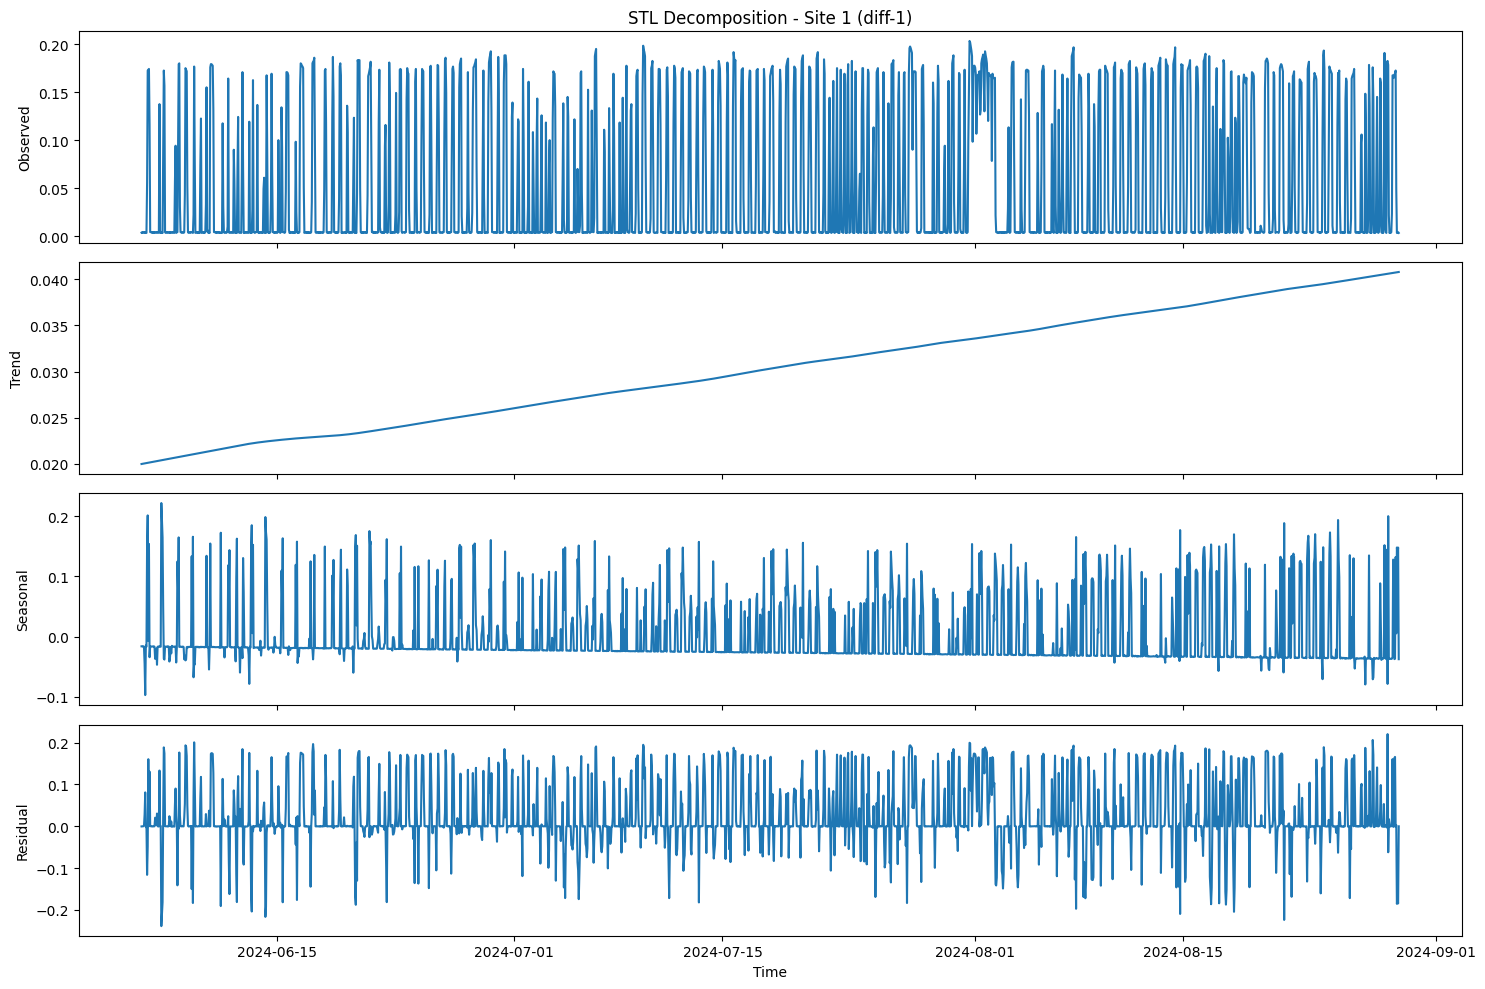


STL Decomposition for Site 2 (diff-1):


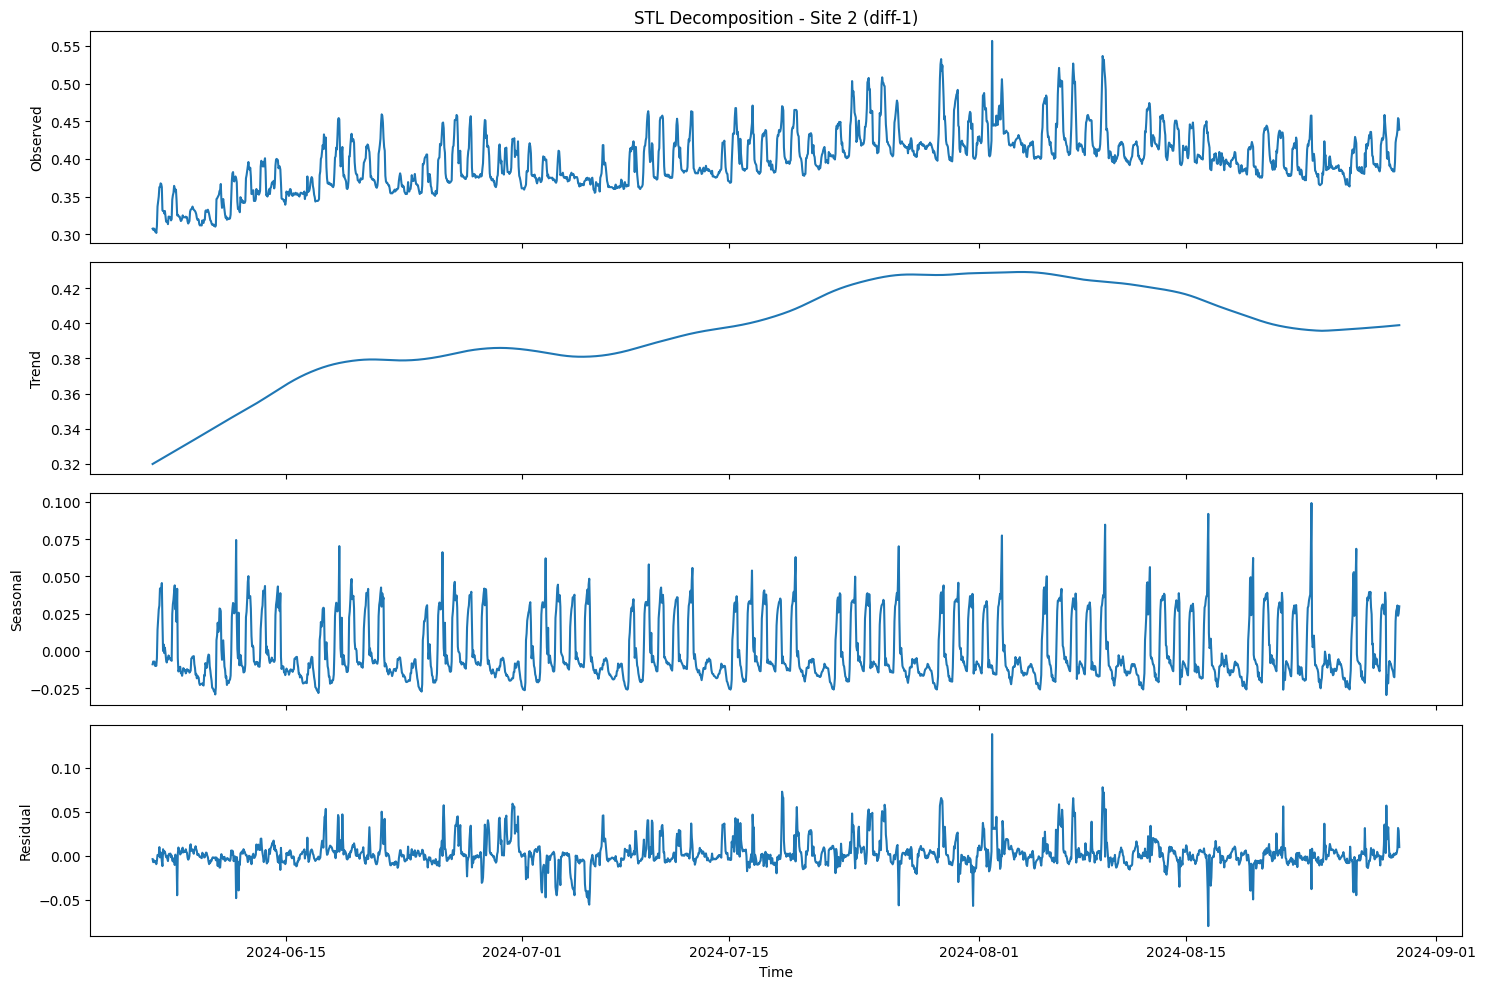


STL Decomposition for Site 3 (diff-1):


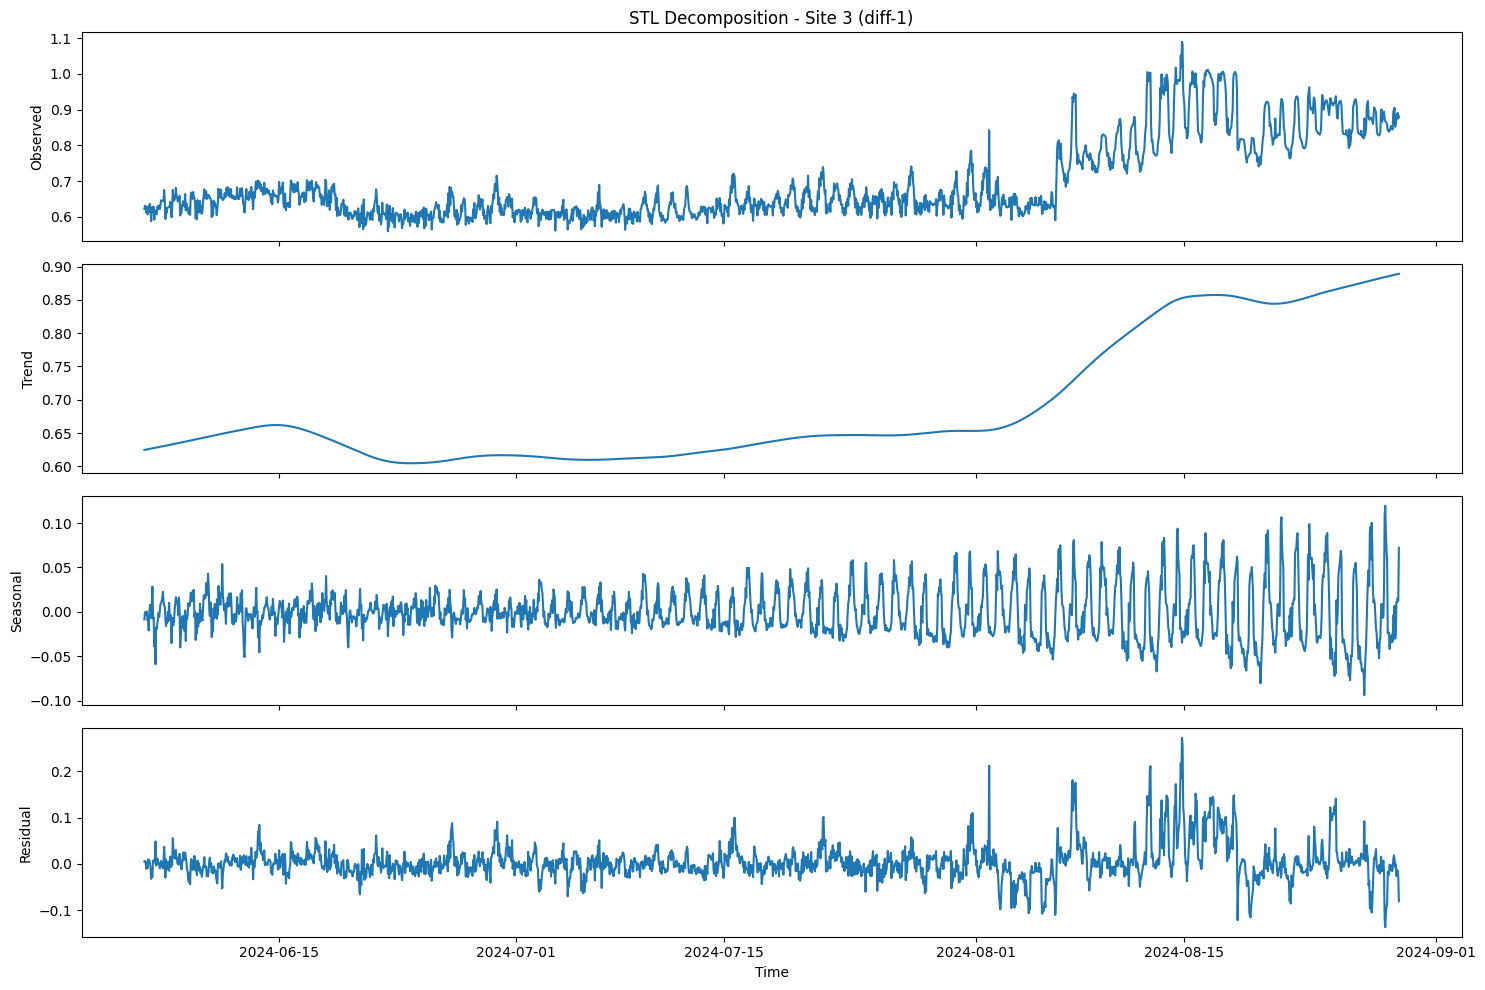

In [111]:
from statsmodels.tsa.seasonal import STL
import matplotlib.dates as mdates

def plot_stl_decomposition(series, site_id, period=168, robust=True, diff=False):
    """Plot STL decomposition for a given time series."""
    # Fill missing values with median for decomposition
    fill_value = series.median() if not pd.isna(series.median()) else 0
    filled_series = series.fillna(fill_value)

    stl = STL(filled_series, period=period, seasonal=int(1.5*period)-1, robust=robust)
    result = stl.fit()

    fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
    axes[0].plot(result.observed)
    axes[0].set_ylabel("Observed")
    axes[1].plot(result.trend)
    axes[1].set_ylabel("Trend")
    axes[2].plot(result.seasonal)
    axes[2].set_ylabel("Seasonal")
    axes[3].plot(result.resid)
    axes[3].set_ylabel("Residual")
    axes[3].set_xlabel("Time")
    diff_label = " (diff-1)" if diff else ""
    axes[0].set_title(f"STL Decomposition - Site {site_id}{diff_label}")
    plt.tight_layout()
    plt.show()

# STL decomposition for each site's hourly data (raw and diff-1)
for i in range(1, 10):
    site_key = f'site_{i}'
    if site_key in site_diff_hourly_data:
        print(f"\nSTL Decomposition for Site {i} (diff-1):")
        plot_stl_decomposition(site_diff_hourly_data[site_key], i, period=168, diff=True)